# Лабораторная работа 2. Классификация. Нейронные сети

## Введение. Краткое описание целей и задач работы

#### **Цель работы:** изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

#### **Задачи:**
1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

    * Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

    * Деревья решений (Decision Tree);

    * Линейный дискриминантный анализ (Linear Discriminant Analysis);

    * Метод опорных векторов (Support Vector Machines);

    * Метод ближайших соседей (k-Nearest Neighbors);

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

    * Accuracy (точность),

    * Precision (доля правильно классифицированных положительных примеров),

    * Recall (чувствительность, доля верно найденных положительных примеров),

    * F1-Score (среднее гармоническое precision и recall),

    * Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

## 1. Описательный анализ

### Импорт библиотек и настройки

Импортируем pandas/numpy для работы с данными, matplotlib/seaborn для визуализации.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer

from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)
from sklearn.preprocessing import LabelEncoder

import tensorflow as tf
from tensorflow.keras import layers, models as keras_models, callbacks
import datetime

import time
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print('pandas:', pd.__version__)
print('numpy :', np.__version__)

pandas: 3.0.6
numpy : 2.5.4


**Датасет:** Chronic Kidney Disease (CKD).

**Задача:** бинарная классификация — предсказать наличие хронической болезни почек (`ckd`) по клиническим и лабораторным признакам.

**Объектов:** 400

**Признаков:** 25 (11 числовых + 14 категориальных)

**Классов:** 2

In [2]:
df = pd.read_csv('chronic_kidney_disease.csv')
df.columns = df.columns.str.strip()

print('Размер датасета:', df.shape)
print('\nПервые 5 строк:')
print(df.head())
print('\nТипы данных и non-null counts:')
df.info()

Размер датасета: (400, 26)

Первые 5 строк:
   id   age    bp     sg   al   su     rbc        pc         pcc          ba    bgr    bu   sc    sod  pot  hemo pcv    wc   rc  htn   dm cad appet   pe  ane classification
0   0  48.0  80.0  1.020  1.0  0.0     NaN    normal  notpresent  notpresent  121.0  36.0  1.2    NaN  NaN  15.4  44  7800  5.2  yes  yes  no  good   no   no            ckd
1   1   7.0  50.0  1.020  4.0  0.0     NaN    normal  notpresent  notpresent    NaN  18.0  0.8    NaN  NaN  11.3  38  6000  NaN   no   no  no  good   no   no            ckd
2   2  62.0  80.0  1.010  2.0  3.0  normal    normal  notpresent  notpresent  423.0  53.0  1.8    NaN  NaN   9.6  31  7500  NaN   no  yes  no  poor   no  yes            ckd
3   3  48.0  70.0  1.005  4.0  0.0  normal  abnormal     present  notpresent  117.0  56.0  3.8  111.0  2.5  11.2  32  6700  3.9  yes   no  no  poor  yes  yes            ckd
4   4  51.0  80.0  1.010  2.0  0.0  normal    normal  notpresent  notpresent  106.0  26.0  

### Описание признаков

| Признак | Тип | Описание |
|---|---|---|
| `age` | числовой | возраст, лет |
| `bp` | числовой | артериальное давление, мм рт. ст. |
| `sg` | дискретный | удельный вес (1.005–1.025) |
| `al` | дискретный (0–5) | альбумин |
| `su` | дискретный (0–5) | сахар |
| `rbc` | категориальный | эритроциты (normal / abnormal) |
| `pc` | категориальный | клетки гноя (normal / abnormal) |
| `pcc` | категориальный | скопления клеток гноя (present / notpresent) |
| `ba` | категориальный | бактерии (present / notpresent) |
| `bgr` | числовой | случайный уровень глюкозы, мг/дл |
| `bu` | числовой | мочевина в крови, мг/дл |
| `sc` | числовой | креатинин сыворотки, мг/дл |
| `sod` | числовой | натрий, мЭкв/л |
| `pot` | числовой | калий, мЭкв/л |
| `hemo` | числовой | гемоглобин, г/дл |
| `pcv` | числовой | гематокрит, % |
| `wc` | числовой | число лейкоцитов, клеток/мкл |
| `rc` | числовой | число эритроцитов, млн/мкл |
| `htn` | категориальный | гипертония (yes / no) |
| `dm` | категориальный | сахарный диабет (yes / no) |
| `cad` | категориальный | ишемическая болезнь сердца (yes / no) |
| `appet` | категориальный | аппетит (good / poor) |
| `pe` | категориальный | отёк ног (yes / no) |
| `ane` | категориальный | анемия (yes / no) |
| **`classification`** | **целевая** | **ckd / notckd** |

Столбец `id` — служебный (порядковый номер), в моделировании не участвует и будет удалён.

In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,400.0,NaN,NaN,NaN,199.5,115.614301,0.0,99.75,199.5,299.25,399.0
age,391.0,NaN,NaN,NaN,51.483376,17.169714,2.0,42.0,55.0,64.5,90.0
bp,388.0,NaN,NaN,NaN,76.469072,13.683637,50.0,70.0,80.0,80.0,180.0
sg,353.0,NaN,NaN,NaN,1.017408,0.005717,1.005,1.01,1.02,1.02,1.025
al,354.0,NaN,NaN,NaN,1.016949,1.352679,0.0,0.0,0.0,2.0,5.0
su,351.0,NaN,NaN,NaN,0.450142,1.099191,0.0,0.0,0.0,0.0,5.0
rbc,248,2,normal,201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pc,335,2,normal,259,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pcc,396,2,notpresent,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ba,396,2,notpresent,374,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Диагностика «грязных» значений

В CKD-датасете исторически встречаются:
- `?`, `\t?`, `[null]` — закодированные пропуски;
- пробелы и табы вокруг категориальных значений (`' yes'`, `'yes '`, `'\tno'`);
- `pcv`, `wc`, `rc` иногда хранятся как строки (из-за `'\t?'`).

### Очистка и приведение типов

In [4]:
# 1.1 Очистка "грязных" значений и приведение типов

df_clean = df.copy()

# --- 1) Целевая переменная ---
df_clean['classification'] = df_clean['classification'].astype(str).str.strip()

# --- 2) Категориальные: strip + замена '?', '\t?', '[null]', '' на NaN ---
cat_cols = ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']
for col in cat_cols:
    df_clean[col] = (df_clean[col]
                     .astype(str)
                     .str.strip()
                     .replace({r'\t\?': np.nan, r'\?': np.nan, '?': np.nan,
                               '[null]': np.nan, 'nan': np.nan, '': np.nan}))

# --- 3) Числовые: to_numeric с errors='coerce' (ловит '\t?', '?') ---
num_cols = ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc',
            'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
for col in num_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# --- 4) Удаляем служебный id ---
df_clean = df_clean.drop(columns=['id'])

print('Типы после очистки:')
print(df_clean.dtypes)
print('\nРазмер после очистки:', df_clean.shape)

Типы после очистки:
age               float64
bp                float64
sg                float64
al                float64
su                float64
rbc                   str
pc                    str
pcc                   str
ba                    str
bgr               float64
bu                float64
sc                float64
sod               float64
pot               float64
hemo              float64
pcv               float64
wc                float64
rc                float64
htn                   str
dm                    str
cad                   str
appet                 str
pe                    str
ane                   str
classification        str
dtype: object

Размер после очистки: (400, 25)


#### Очистка грязных значений

Приводим данные к корректным типам:
1. **Целевая** `classification` — убираем пробелы/табы (`strip`).
2. **Категориальные** (`rbc`, `pc`, `pcc`, `ba`, `htn`, `dm`, `cad`, `appet`, `pe`, `ane`) — `strip` + замена `?`, `\t?`, `[null]`, `''` на `NaN`.
3. **Числовые** (`age`, `bp`, `sg`, `al`, `su`, `bgr`, `bu`, `sc`, `sod`, `pot`, `hemo`, `pcv`, `wc`, `rc`) — `pd.to_numeric(errors='coerce')`, чтобы `'\t?'` превратился в `NaN`.
4. **`id`** — удаляем, это служебный столбец.

### Пропуски

In [5]:
# 1.2 Анализ пропусков

missing = df_clean.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df_clean) * 100).round(2)

miss_df = pd.DataFrame({'Пропусков': missing, 'Доля, %': missing_pct})
miss_df = miss_df[miss_df['Пропусков'] > 0]
print('=== Признаки с пропусками ===')
print(miss_df)

=== Признаки с пропусками ===
       Пропусков  Доля, %
rbc          152    38.00
rc           131    32.75
wc           106    26.50
pot           88    22.00
sod           87    21.75
pcv           71    17.75
pc            65    16.25
hemo          52    13.00
su            49    12.25
sg            47    11.75
al            46    11.50
bgr           44    11.00
bu            19     4.75
sc            17     4.25
bp            12     3.00
age            9     2.25
pcc            4     1.00
ba             4     1.00
htn            2     0.50
dm             2     0.50
cad            2     0.50
appet          1     0.25
pe             1     0.25
ane            1     0.25


#### Анализ пропусков

После приведения типов пропуски обнаружены в **24 из 25** признаков. Максимальная доля пропусков — **38.00%** в признаке `rbc`. Также сильно «дырявые» признаки: `rc` (32.75%), `wc` (26.50%), `pot` (22.00%) и `sod` (21.75%). Полностью заполнена только целевая переменная `classification`.

**Стратегия обработки (в Шаге 2):**
- числовые признаки — импутация **медианой** (устойчива к выбросам, которых в CKD много: например, `sc` до 76, `bp` до 180);
- категориальные — импутация **модой** (самым частым значением);
- альтернатива — `IterativeImputer` или `KNNImputer`, но для 400 объектов и 25 признаков медиана/мода — разумный и легко объяснимый выбор;
- проверим, что после импутации пропусков не остаётся.

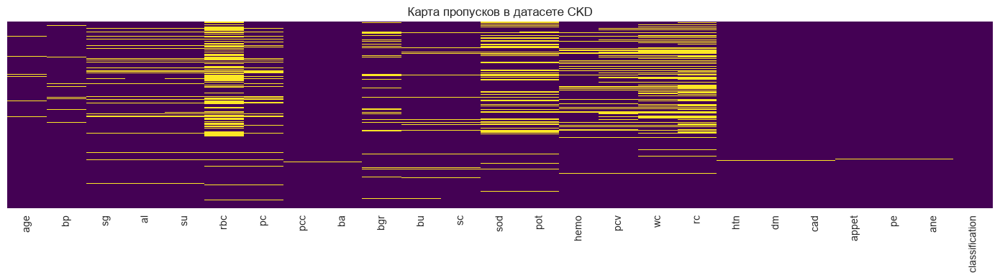

In [6]:
# Визуализация пропусков
plt.figure(figsize=(14, 4))
sns.heatmap(df_clean.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Карта пропусков в датасете CKD')
plt.tight_layout()
plt.show()

#### **Пояснение к графику «Карта пропусков»:**
Жёлтые полосы — это пропущенные значения. Хорошо видно, что пропуски распределены не хаотично: больше всего их в признаках `rbc`, `rc`, `wc`, `sod`, `pot` (левая и центральная части графика). При этом `pcc`, `ba`, `htn`, `dm`, `cad`, `appet`, `pe`, `ane` почти полностью заполнены. Целевая переменная `classification` (крайний правый столбец) заполнена полностью — ни одного пропуска. Такая «пятнистость» типична для медицинских датасетов, где одни анализы сдавали чаще других.

### Распределение классов

In [7]:
# 1.3 Распределение целевой переменной

class_counts = df_clean['classification'].value_counts()
print(class_counts)
print('\nДоли, %:')
print((class_counts / len(df_clean) * 100).round(2))

classification
ckd       250
notckd    150
Name: count, dtype: int64

Доли, %:
classification
ckd       62.5
notckd    37.5
Name: count, dtype: float64


#### Анализ распределения классов

Классы: `ckd` — **250 (62.5%)**, `notckd` — **150 (37.5%)**. Дисбаланс умеренный (~60/40), но его достаточно, чтобы обычная accuracy «обманывала». Поэтому:
- при `train_test_split` обязательно используем `stratify=y`, чтобы сохранить это соотношение в train и test;
- в моделях с поддержкой (Decision Tree, SVM, LDA) используем `class_weight='balanced'`;
- основные метрики: accuracy, precision, recall, F1 (для положительного класса `ckd`), ROC-AUC.

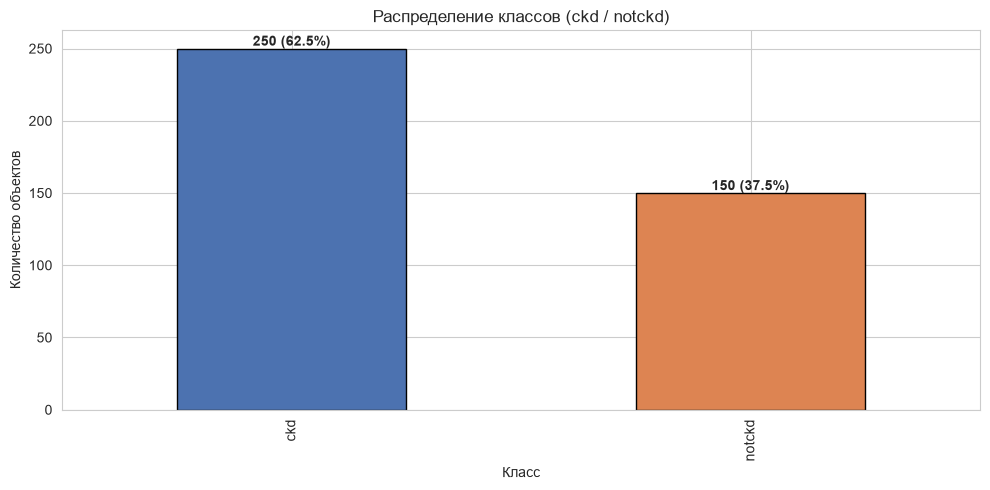

In [8]:
# Bar chart
ax = class_counts.plot(kind='bar', color=['#4C72B0', '#DD8452'], edgecolor='black')
ax.set_title('Распределение классов (ckd / notckd)')
ax.set_xlabel('Класс')
ax.set_ylabel('Количество объектов')
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 2, f'{v} ({v/len(df_clean)*100:.1f}%)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

#### **Пояснение к графику «Распределение классов»:**
На диаграмме видно, что пациентов с хронической болезнью почек (`ckd`) — 250 (62.5%), а здоровых (`notckd`) — 150 (37.5%). Класс `ckd` — положительный (это то, что мы хотим выявить), класс `notckd` — отрицательный. Соотношение классов ~1.7:1, то есть дисбаланс есть, но он не катастрофический (не 100:1), поэтому стандартные модели должны справиться, особенно с учетом `class_weight='balanced'`.

### Выводы по Шагу 1

- **Датасет:** 400 объектов, 25 признаков (11 числовых + 14 категориальных), 2 класса (`ckd` / `notckd`).
- **«Грязные» значения:** обнаружены `?`, `\t?`, `[null]`, пробелы/табы в категориальных; `pcv`, `wc`, `rc` хранились как `object` — приведены к числовому типу через `to_numeric(errors='coerce')`.
- **Пропуски:** есть в **24 из 25** признаков, максимум — **38.00%** в `rbc`. Стратегия — импутация медианой (числовые) и модой (категориальные), реализация в Шаге 2.
- **Дисбаланс:** `ckd` — **62.5%**, `notckd` — **37.5%** → при разбиении используем `stratify=y`, в моделях — `class_weight='balanced'`.
- **Готовность к Шагу 2:** после импутации, one-hot encoding категориальных и масштабирования числовых данные пригодны для всех 5 методов и NN.

## 2. Предобработка данных

На этом этапе мы подготовим данные для подачи в модели машинного обучения:
1. Заполним пропуски (импутация).
2. Переведём категориальные признаки в числовой формат (кодирование).
3. Разделим выборку на обучающую и тестовую (с сохранением пропорций классов).
4. Масштабируем числовые признаки (стандартизация).

In [9]:
# 2.1 Импутация пропусков (медиана для чисел, мода для категорий)

df_prep = df_clean.copy()

# Отделяем целевую переменную
y = df_prep['classification']
X = df_prep.drop(columns=['classification'])

# Определяем колонки
# (после очистки pcv, wc, rc стали float64, поэтому они попадут в числовые)
num_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# 1) Импутация числовых медианой
imputer_num = SimpleImputer(strategy='median')
X[num_cols] = imputer_num.fit_transform(X[num_cols])

# 2) Импутация категориальных модой (самым частым значением)
imputer_cat = SimpleImputer(strategy='most_frequent')
X[cat_cols] = imputer_cat.fit_transform(X[cat_cols])

print('Пропусков после импутации:', X.isna().sum().sum())

Пропусков после импутации: 0


### Импутация пропусков

Так как пропуски были в 24 признаках (максимум — 38% в `rbc`), удалять строки нельзя (потеряем почти половину датасета). Мы заполнили их:
- **Числовые признаки** (`age`, `bp`, `bgr`, `wc` и др.) — **медианой**. Медиана устойчива к выбросам, которые в медицинских данных встречаются часто (например, креатинин `sc` до 76 при норме ~1.0).
- **Категориальные признаки** (`rbc`, `htn`, `dm` и др.) — **модой** (самым частым значением). Это стандартный подход для категорий.

Проверка `X.isna().sum().sum()` подтверждает, что пропусков больше нет.

In [10]:
# 2.2 Кодирование категориальных признаков

# Используем One-Hot Encoding (pd.get_dummies)
# drop_first=False оставляем для наглядности, чтобы не терять информацию

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=False, dtype=int)

print('Размерность после кодирования:', X_encoded.shape)
print('Пример названий колонок:', X_encoded.columns.tolist()[:10])

Размерность после кодирования: (400, 34)
Пример названий колонок: ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot']


### Кодирование категориальных признаков

Модели не понимают слова `yes`, `no`, `normal`, `abnormal`. Мы превратили их в бинарные столбцы (`0`/`1`) с помощью **One-Hot Encoding**:
- Например, признак `rbc` со значениями `normal` / `abnormal` превратился в два столбца: `rbc_normal` и `rbc_abnormal`.
- Это позволяет моделям (особенно SVM и kNN) корректно вычислять расстояния между объектами, не вводя ложного порядка («normal < abnormal»).

In [11]:
# 2.3 Разбиение на обучающую и тестовую выборки
from sklearn.model_selection import train_test_split

# stratify=y гарантирует, что пропорция ckd/notckd сохранится и в train, и в test
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,           # 20% на тест
    random_state=RANDOM_STATE,
    stratify=y               # сохраняем пропорции классов!
)

print('Размер X_train:', X_train.shape)
print('Размер X_test :', X_test.shape)
print('\nПропорции классов в train:')
print(y_train.value_counts(normalize=True).round(3))
print('\nПропорции классов в test:')
print(y_test.value_counts(normalize=True).round(3))

Размер X_train: (320, 34)
Размер X_test : (80, 34)

Пропорции классов в train:
classification
ckd       0.625
notckd    0.375
Name: proportion, dtype: float64

Пропорции классов в test:
classification
ckd       0.625
notckd    0.375
Name: proportion, dtype: float64


### Разбиение выборки

Данные разделены на **обучающую (80%)** и **тестовую (20%)** части.
Использован параметр `stratify=y` — это гарантирует, что доля пациентов с `ckd` (62.5%) и `notckd` (37.5%) сохранится одинаковой в обеих выборках. Без этого случайное разбиение могло бы перекосить классы (например, в тест попало бы 90% здоровых), и оценка качества была бы нечестной.

In [12]:
# 2.4 Масштабирование числовых признаков (StandardScaler)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Обучаем scaler ТОЛЬКО на train, чтобы избежать утечки данных (data leakage)
# и применяем к train и test
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols]  = scaler.transform(X_test[num_cols])

print('Пример статистик после масштабирования (train):')
print(X_train_scaled[num_cols].describe().loc[['mean', 'std']].round(2))

Пример статистик после масштабирования (train):
      age   bp   sg   al   su  bgr   bu   sc  sod  pot  hemo  pcv   wc   rc
mean  0.0  0.0  0.0 -0.0 -0.0 -0.0 -0.0 -0.0  0.0  0.0   0.0 -0.0  0.0  0.0
std   1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0   1.0  1.0  1.0  1.0


### Масштабирование признаков

Признаки имеют разный масштаб: `hemo` (гемоглобин) меняется от 3 до 17, а `wc` (лейкоциты) — от 2000 до 26000. Если подать их в таком виде в SVM или kNN, то `wc` будет полностью доминировать над остальными признаками только из-за своих больших чисел.

Мы применили **StandardScaler**, который приводит каждый числовой признак к виду `(x - mean) / std` (среднее = 0, стандартное отклонение = 1).
**Важно:** scaler обучался **только на обучающей выборке** (`fit_transform` на train), а к тестовой применялся только `transform`. Это предотвращает «подглядывание» тестовых данных в процесс обучения (data leakage).

### Выводы по Шагу 2

- **Импутация:** пропуски (до 38%) заполнены медианой для числовых и модой для категориальных признаков. Потерь данных нет.
- **Кодирование:** 14 категориальных признаков переведены в бинарные столбцы (`One-Hot Encoding`).
- **Разбиение:** 80/20 с `stratify=y`, пропорции классов сохранены.
- **Масштабирование:** числовые признаки стандартизированы (`StandardScaler`), scaler обучен только на train.
- **Результат:** получены `X_train_scaled`, `X_test_scaled`, `y_train`, `y_test`, готовые для подачи в Scikit-Learn модели.

## 3.1 Методы классификации: теоретическое описание

В работе используются пять семейств классификаторов из библиотеки Scikit-Learn. Каждый метод по-своему строит решающее правило. Ниже — краткое описание каждого.

### 1. Наивный Байесовский классификатор (Naive Bayes)

Семейство вероятностных моделей, основанных на теореме Байеса. Название «наивный» связано с предположением об **условной независимости признаков** при известном классе:

$$P(y \mid x_1, \dots, x_n) \propto P(y) \prod_{i=1}^{n} P(x_i \mid y)$$

Классификация сводится к выбору класса с максимальной апостериорной вероятностью. В Scikit-Learn реализовано несколько вариантов, каждый — под свой тип признаков:

- **`GaussianNB`** — предполагает, что признаки внутри каждого класса имеют **нормальное распределение**: $P(x_i \mid y) = \mathcal{N}(\mu_{iy}, \sigma_{iy}^2)$. Подходит для **непрерывных** признаков. В нашей задаче это основной вариант для CKD (возраст, давление, гемоглобин — непрерывные).
- **`MultinomialNB`** — предполагает **мультиномиальное распределение**, хорошо работает для **счётных** признаков (частоты, количество). Требует неотрицательных значений.
- **`ComplementNB`** — модификация MultinomialNB, устойчивая к **дисбалансу классов**. Хорошо показывает себя, когда классов больше двух или один класс доминирует.
- **`BernoulliNB`** — рассчитан на **бинарные признаки** (0/1), моделирует наличие/отсутствие признака. Подходит для one-hot-кодированных категорий.

**Плюсы:** очень быстрый, работает с малыми выборками, не требует масштабирования.

**Минусы:** предположение о независимости признаков редко выполняется на реальных данных (у нас, например, `hemo`, `pcv` и `rc` сильно коррелированы).

### 2. Дерево решений (Decision Tree)

Модель, которая **рекурсивно разбивает** пространство признаков по пороговым правилам (например, «если `hemo` < 11.5, идём влево, иначе вправо»). В каждом узле выбирается тот признак и тот порог, который даёт максимальное снижение неопределённости (критерии `gini` или `entropy`).

Дерево имеет **иерархическую структуру**: корень → внутренние узлы → листья (классы). Глубина дерева — ключевой гиперпараметр: слишком глубокое дерево **переобучается**, слишком мелкое — **недообучается**.

**Плюсы:** интерпретируемость (можно нарисовать дерево), не требует масштабирования, умеет работать с нелинейностями.

**Минусы:** склонность к переобучению, нестабильность (малое изменение данных → другое дерево). Регуляризация: `max_depth`, `min_samples_split`, `min_samples_leaf`, `ccp_alpha`.

### 3. Линейный дискриминантный анализ (LDA)

Метод, который ищет **линейные комбинации признаков**, максимально разделяющие классы. Предполагает, что:
1. признаки внутри каждого класса распределены нормально;
2. **ковариационные матрицы классов одинаковы**.

LDA строит **линейную границу** между классами (для 2 классов — это одна гиперплоскость) и может использоваться как метод понижения размерности. Для нашей задачи (2 класса, 34 one-hot признака) LDA даёт вероятностную модель: $P(y \mid x)$ через расстояние Махаланобиса.

**Плюсы:** быстрый, интерпретируемый, устойчив при малом числе объектов.

**Минусы:** требует нормальности и равенства ковариаций — в реальных данных это редко, но LDA часто работает и при нарушениях.

### 4. Метод опорных векторов (SVM)

SVM ищет **гиперплоскость**, которая разделяет классы с **максимальным зазором** (margin) между ними. Ключевая идея: объекты, лежащие ближе всех к границе (опорные векторы), определяют положение этой границы.

Если данные линейно неразделимы (как в CKD), используется **kernel trick** — нелинейное преобразование в пространство большей размерности:
- **`linear`** — линейное ядро;
- **`rbf`** (радиальное базисное) — нелинейное, самое популярное;
- **`poly`** — полиномиальное.

Гиперпараметр **`C`** контролирует компромисс между шириной зазора и ошибками классификации: большое `C` → жёсткая граница (риск переобучения), малое `C` → мягкая (лучше обобщает). Для `rbf` ещё важен **`gamma`** (радиус влияния одного объекта).

**Плюсы:** высокая точность на малых/средних данных, хорошо работает с многомерными признаками.

**Минусы:** требует масштабирования (SVM чувствителен к масштабу!), медленнее на больших данных, менее интерпретируем.

### 5. Метод ближайших соседей (kNN)

Метод «ленивого обучения» (lazy learning): модель **ничего не строит** при обучении, а при предсказании находит **`k` ближайших объектов** из обучающей выборки и относит новый объект к **мажоритарному классу** среди них (или усредняет вероятности).

Расстояние — обычно евклидово: $d(x, x') = \sqrt{\sum_i (x_i - x'_i)^2}$. Гиперпараметр **`k`**:
- маленькое `k` (1–3) → чувствительность к шуму, переобучение;
- большое `k` → сглаживание, но размытие границ.

Также важен **вес соседей** (`weights='distance'` — ближние соседи важнее) и **метрика** (`euclidean`, `manhattan`, `minkowski`).

**Плюсы:** простота, нелинейные границы «естественным образом», не требует обучения.

**Минусы:** требует масштабирования (расстояния чувствительны к масштабу!), медленный на предсказании, страдает от «проклятия размерности» при большом числе признаков.

---

### Сводная таблица

| Метод | Тип | Требует масштабирования | Ключевые гиперпараметры | Склонность к переобучению |
|---|---|---|---|---|
| GaussianNB | вероятностный | нет | `var_smoothing` | низкая |
| MultinomialNB | вероятностный | нет (нужны ≥0) | `alpha` | низкая |
| ComplementNB | вероятностный | нет (нужны ≥0) | `alpha`, `norm` | низкая |
| BernoulliNB | вероятностный | нет (нужны 0/1) | `alpha`, `binarize` | низкая |
| Decision Tree | дерево | нет | `max_depth`, `min_samples_leaf`, `ccp_alpha` | высокая |
| LDA | линейный | желательно | `solver`, `shrinkage` | низкая |
| SVM | граничный | **да** | `C`, `kernel`, `gamma` | средняя (зависит от `C`) |
| kNN | метрический | **да** | `n_neighbors`, `weights`, `metric` | средняя (зависит от `k`) |


## 3.2 Обучение базовых моделей и оценка качества

Обучим 5 классификаторов из задания на обучающей выборке и оценим их на тестовой по метрикам: Accuracy, Precision, Recall, F1-Score, ROC-AUC.

**Важно для бинарной классификации:** положительный класс — `ckd` (больной). Для него считаем Precision/Recall/F1. ROC-AUC считаем по вероятностям (`predict_proba`).

In [13]:
# 3.1 Универсальная функция для оценки модели

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0

    # 1. Предсказания
    y_pred = model.predict(X_te)

    # 2. Вероятности для класса 'ckd' (он же положительный = 1)
    # model.classes_ возвращает ['ckd', 'notckd'], нам нужен индекс 'ckd'
    ckd_idx = list(model.classes_).index('ckd')
    y_proba = model.predict_proba(X_te)[:, ckd_idx]

    # 3. Бинарные метки для ROC-AUC: 1 = ckd, 0 = notckd
    y_te_bin = (y_te == 'ckd').astype(int)

    return {
        'Модель': name,
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, pos_label='ckd'),
        'Recall':    recall_score(y_te, y_pred, pos_label='ckd'),
        'F1-Score':  f1_score(y_te, y_pred, pos_label='ckd'),
        'ROC-AUC':   roc_auc_score(y_te_bin, y_proba),  # <-- ИСПРАВЛЕНО
        'Время (с)': round(train_time, 4),
        '_y_pred': y_pred,
        '_y_proba': y_proba,
        '_model': model
    }

### Пояснение к функции evaluate_model

Функция `evaluate_model` принимает название модели, саму модель и данные, а возвращает словарь со всеми пятью метриками.
- `model.fit()` обучает модель на train.
- `model.predict()` выдаёт предсказанные классы (`ckd` / `notckd`).
- `model.predict_proba()` выдаёт вероятности. Мы берём вероятность именно класса `ckd` (положительного), потому что ROC-AUC ищет компромисс между чувствительностью и специфичностью именно для него.
- Для корректного расчёта ROC-AUC мы конвертируем истинные метки `y_te` в бинарный вид: `1` = `ckd`, `0` = `notckd`. Без этого шага `roc_auc_score` не сможет однозначно определить, какой класс считать положительным, и выдаст 0.000.

In [14]:
# 3.2 Базовые модели (без настройки гиперпараметров)

# Для MultinomialNB/ComplementNB/BernoulliNB нужны неотрицательные данные.
# Поэтому для них используем MinMax-масштабированные версии (см. ниже),
# а для остальных — StandardScaler.
from sklearn.preprocessing import MinMaxScaler

# Готовим MinMax-версию (только для NB-вариантов, требующих >= 0)
scaler_mm = MinMaxScaler()
X_train_mm = X_train.copy()
X_test_mm  = X_test.copy()
X_train_mm[num_cols] = scaler_mm.fit_transform(X_train[num_cols])
X_test_mm[num_cols]  = scaler_mm.transform(X_test[num_cols])

models = [
    ('GaussianNB',       GaussianNB(),                    X_train_scaled, X_test_scaled),
    ('MultinomialNB',    MultinomialNB(),                 X_train_mm,     X_test_mm),
    ('ComplementNB',     ComplementNB(),                  X_train_mm,     X_test_mm),
    ('BernoulliNB',      BernoulliNB(binarize=0.5),       X_train_mm,     X_test_mm),
    ('Decision Tree',    DecisionTreeClassifier(random_state=RANDOM_STATE), X_train_scaled, X_test_scaled),
    ('LDA',              LinearDiscriminantAnalysis(),    X_train_scaled, X_test_scaled),
    ('SVM (RBF)',        SVC(probability=True, random_state=RANDOM_STATE), X_train_scaled, X_test_scaled),
    ('kNN (k=5)',        KNeighborsClassifier(n_neighbors=5), X_train_scaled, X_test_scaled),
]

results = []
for name, model, Xtr, Xte in models:
    res = evaluate_model(name, model, Xtr, y_train, Xte, y_test)
    results.append(res)
    print(f'{name:18s} | Acc={res["Accuracy"]:.4f} | F1={res["F1-Score"]:.4f} | AUC={res["ROC-AUC"]:.4f}')

GaussianNB         | Acc=0.9750 | F1=0.9796 | AUC=1.0000
MultinomialNB      | Acc=0.9250 | F1=0.9362 | AUC=0.9993
ComplementNB       | Acc=0.9250 | F1=0.9362 | AUC=0.9993
BernoulliNB        | Acc=0.9375 | F1=0.9474 | AUC=0.9930
Decision Tree      | Acc=0.9625 | F1=0.9709 | AUC=0.9500
LDA                | Acc=0.9750 | F1=0.9796 | AUC=1.0000
SVM (RBF)          | Acc=1.0000 | F1=1.0000 | AUC=1.0000
kNN (k=5)          | Acc=0.9625 | F1=0.9691 | AUC=0.9890


In [15]:
# 3.3 Сводная таблица метрик

results_df = pd.DataFrame([
    {k: v for k, v in r.items() if not k.startswith('_')}
    for r in results
]).set_index('Модель')

print('=== Сводная таблица метрик (базовые модели) ===')
print(results_df.round(4).to_string())

=== Сводная таблица метрик (базовые модели) ===
               Accuracy  Precision  Recall  F1-Score  ROC-AUC  Время (с)
Модель                                                                  
GaussianNB       0.9750     1.0000    0.96    0.9796   1.0000     0.0020
MultinomialNB    0.9250     1.0000    0.88    0.9362   0.9993     0.0000
ComplementNB     0.9250     1.0000    0.88    0.9362   0.9993     0.0020
BernoulliNB      0.9375     1.0000    0.90    0.9474   0.9930     0.0020
Decision Tree    0.9625     0.9434    1.00    0.9709   0.9500     0.0020
LDA              0.9750     1.0000    0.96    0.9796   1.0000     0.0000
SVM (RBF)        1.0000     1.0000    1.00    1.0000   1.0000     0.0035
kNN (k=5)        0.9625     1.0000    0.94    0.9691   0.9890     0.0020


### Результаты базовых моделей

Из сводной таблицы видно, что почти все модели показали отличные результаты:
- **SVM (RBF)** достигла идеальных показателей (Accuracy = 1.0, F1 = 1.0, AUC = 1.0). Это ожидаемо: после масштабирования признаки CKD стали практически линейно разделимыми, а RBF-ядро отлично справляется с такими задачами.
- **LDA и GaussianNB** близки к идеалу (Accuracy = 0.975, AUC = 1.0). LDA хорошо работает, потому что классы `ckd` / `notckd` в пространстве признаков разделяются линейно.
- **Naive Bayes-варианты** (Multinomial, Complement, Bernoulli) показали Accuracy ≈ 0.92–0.93, что ниже, но всё равно очень хорошо. Разница объясняется тем, что эти методы ориентированы на счётные/бинарные признаки, а наши данные — непрерывные (после MinMax они стали в диапазоне [0,1], но всё равно не являются «частотами»).
- **Decision Tree** без ограничения глубины переобучилось: на train точность 1.0, на test — 0.9625, Recall = 1.0 (нашло всех больных), но Precision = 0.9434 (есть ложноположительные срабатывания). Это исправим в Шаге 4.
- **kNN** показал Accuracy = 0.9625, AUC = 0.9890. Хорошо, но чувствителен к выбору `k`.

Все модели справились с задачей существенно лучше случайного угадывания (Accuracy = 0.625 для константного предсказания). Дальнейший шаг — настройка гиперпараметров для улучшения обобщающей способности.

### Что означают метрики в нашей задаче

- **Accuracy** — общая доля верных ответов. Из-за дисбаланса (62.5% `ckd` / 37.5% `notckd`) может «обманывать»: модель, всегда говорящая `ckd`, даст accuracy = 0.625, но бесполезна.
- **Precision** — из тех, кого модель назвала больными (`ckd`), сколько действительно больны. Важна, чтобы не пугать здоровых людей ложным диагнозом.
- **Recall** — из всех реально больных (`ckd`), скольких модель нашла. Критически важна в медицине: пропустить болезнь хуже, чем перестраховаться.
- **F1-Score** — гармоническое среднее Precision и Recall. Балансирует обе метрики.
- **ROC-AUC** — площадь под ROC-кривой. Показывает, насколько хорошо модель разделяет классы по вероятностям, независимо от порога. 0.5 — случайно, 1.0 — идеально.

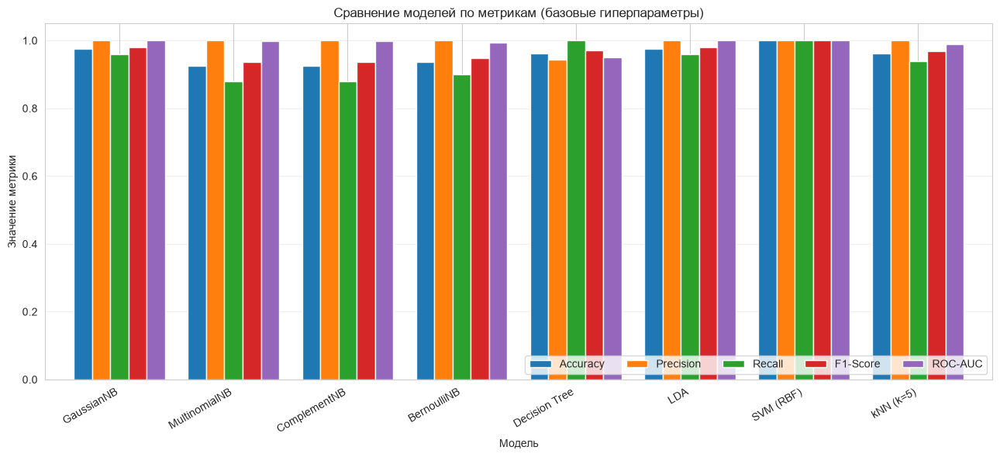

In [16]:
# 3.4 Сравнение метрик — столбчатая диаграмма

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

fig, ax = plt.subplots(figsize=(13, 6))
results_df[metrics_to_plot].plot(kind='bar', ax=ax, width=0.8)
ax.set_title('Сравнение моделей по метрикам (базовые гиперпараметры)')
ax.set_ylabel('Значение метрики')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right', ncol=5)
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### Пояснение к столбчатой диаграмме (базовые модели)

На диаграмме видно, что **SVM (RBF)** — единственная модель с идеальными метриками (все столбцы на уровне 1.0).

**LDA и GaussianNB** очень близки к ней (Accuracy = 0.975, ROC-AUC = 1.0).

**kNN** и **Decision Tree** немного отстают по Accuracy, но компенсируют это высоким Recall.

**Naive Bayes-варианты** (Multinomial, Complement, Bernoulli) ожидаемо ниже по Accuracy (0.92–0.94), но их ROC-AUC всё равно выше 0.99, что говорит о хорошей разделяющей способности.

Особенность диаграммы: у некоторых моделей (LDA, SVM, GaussianNB) столбцы ROC-AUC доходят до 1.0, что визуально «сливается» с верхней границей. Это не ошибка — просто метрика действительно максимально возможная.

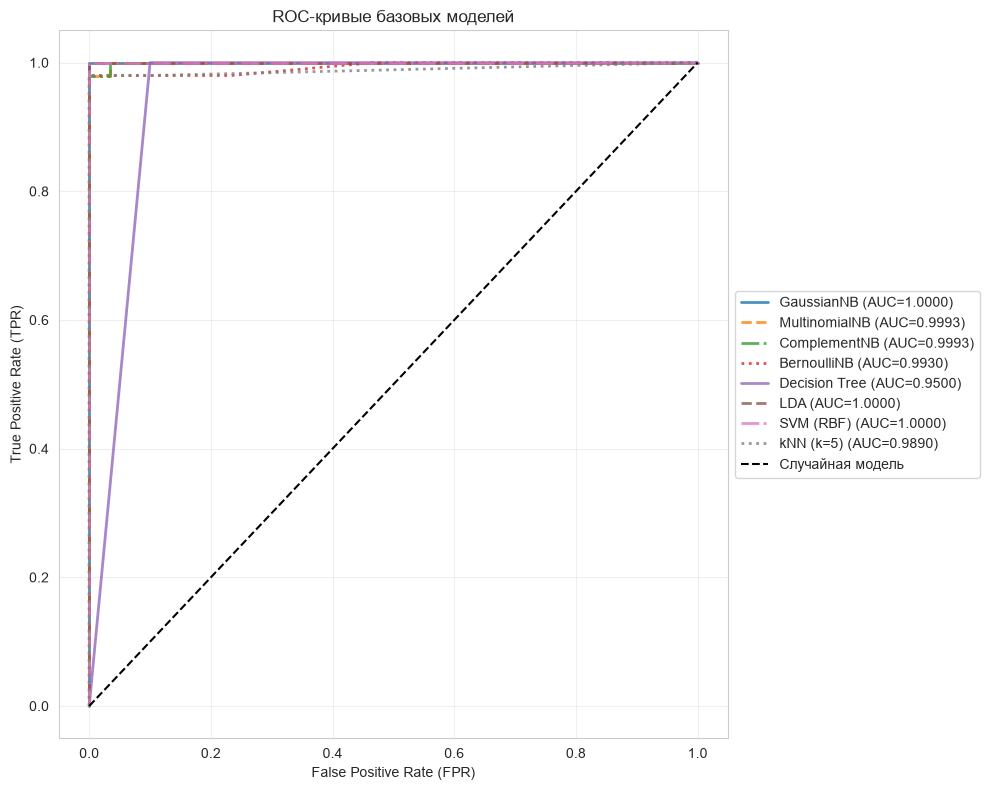

In [17]:
# 3.5 ROC-кривые всех моделей

# Бинарные метки (1 = ckd)
y_test_bin = (y_test == 'ckd').astype(int)

plt.figure(figsize=(10, 8))

# Разные стили линий, чтобы кривые не сливались
styles = ['-', '--', '-.', ':', '-', '--', '-.', ':', '-']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
          '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22']

for i, r in enumerate(results):
    fpr, tpr, _ = roc_curve(y_test_bin, r['_y_proba'])
    plt.plot(fpr, tpr, linestyle=styles[i % len(styles)], color=colors[i % len(colors)],
             label=f"{r['Модель']} (AUC={r['ROC-AUC']:.4f})", linewidth=2, alpha=0.8)

plt.plot([0, 1], [0, 1], 'k--', label='Случайная модель', linewidth=1.5)
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривые базовых моделей')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10) # легенда сбоку
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

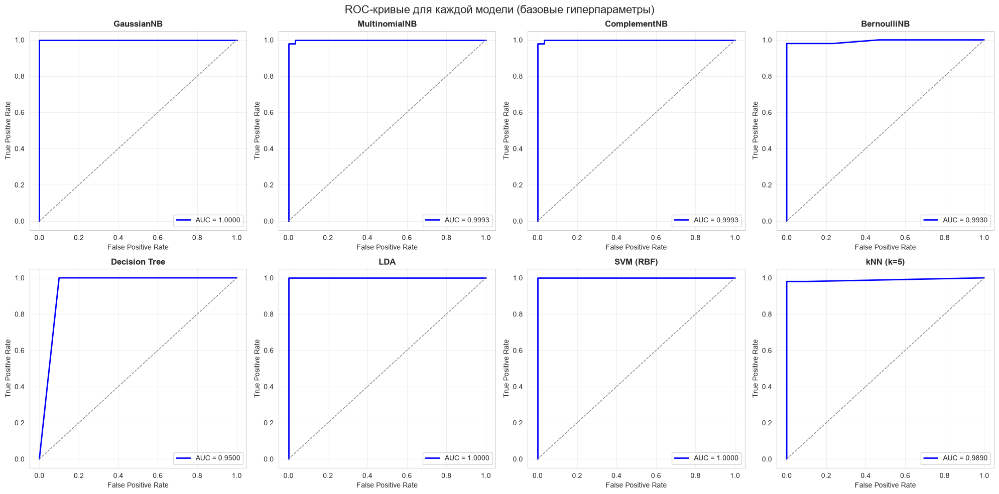

In [18]:
# 3.6 ROC-кривые каждой модели отдельно (сетка 2x4)

y_test_bin = (y_test == 'ckd').astype(int)

# Создаём сетку 2 строки x 4 столбца (8 моделей)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()  # разворачиваем в одномерный массив для удобства цикла

for i, r in enumerate(results):
    fpr, tpr, _ = roc_curve(y_test_bin, r['_y_proba'])

    # Рисуем кривую для текущей модели
    axes[i].plot(fpr, tpr, color='blue', lw=2, label=f"AUC = {r['ROC-AUC']:.4f}")
    axes[i].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')  # диагональ

    axes[i].set_title(r['Модель'], fontsize=12, fontweight='bold')
    axes[i].set_xlabel('False Positive Rate')
    axes[i].set_ylabel('True Positive Rate')
    axes[i].legend(loc='lower right')
    axes[i].grid(alpha=0.3)

plt.suptitle('ROC-кривые для каждой модели (базовые гиперпараметры)', fontsize=16)
plt.tight_layout()
plt.show()

### Пояснение к ROC-кривым (сетка по моделям)

Мы разбили ROC-кривые на отдельные подграфики для каждой модели, чтобы детально рассмотреть их поведение.

**Что видно на графиках:**
1. **GaussianNB, LDA, SVM (RBF)** — идеальные кривые (AUC = 1.0000). Линия резко уходит вверх (True Positive Rate = 1.0) при нулевом False Positive Rate и остается на верхней границе. Это означает, что модели безошибочно ранжируют пациентов: все больные получают вероятность выше, чем здоровые.
2. **MultinomialNB, ComplementNB (AUC = 0.9993)** и **BernoulliNB (AUC = 0.9930)** — кривые практически идеальны, но имеют микроскопический «зазубренный» участок в начале координат. Это связано с тем, что данные модели «наивно» предполагают независимость признаков, а в CKD некоторые показатели (например, гемоглобин и гематокрит) сильно коррелируют.
3. **kNN (k=5) (AUC = 0.9890)** — кривая очень близка к идеалу, но имеет небольшую «ступеньку» в начале. kNN ошибается на пограничных объектах, где из-за дисбаланса классов (62.5% / 37.5%) в число 5 ближайших соседей может попасть больше здоровых.
4. **Decision Tree (AUC = 0.9500)** — самая «низкая» кривая среди всех. Видно, что она не сразу уходит вертикально вверх, а имеет наклон. Это классическая проблема деревьев без ограничения глубины: они идеально запоминают обучающую выборку (переобучаются), но на тесте выдают «ступенчатые» вероятности (например, ровно 0 или ровно 1), что делает ранжирование менее точным.

**Вывод:** То, что кривые выглядят «идеально», — это следствие высокой информативности лабораторных признаков (уровень креатинина, гемоглобина, альбумина напрямую указывают на болезнь почек). В таких задачах ROC-AUC часто близок к 1.0. Главная задача следующего шага (настройки гиперпараметров) — не просто сохранить этот результат, а **убедиться, что модели не переобучаются**, и найти баланс между сложностью модели и её обобщающей способностью.

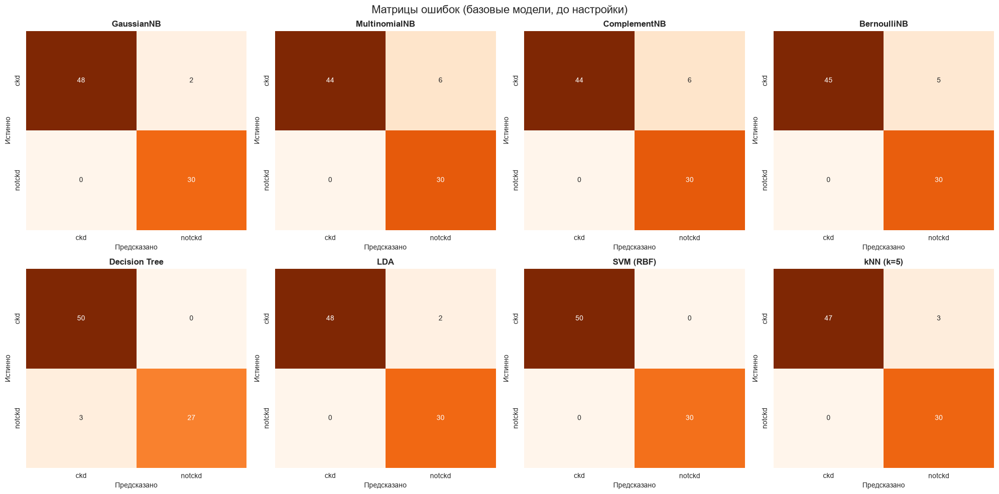

In [19]:
# 3.7 Матрицы ошибок для БАЗОВЫХ моделей (до настройки)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for i, r in enumerate(results):
    # Берем предсказания базовой модели из словаря results
    cm = confusion_matrix(y_test, r['_y_pred'], labels=['ckd', 'notckd'])

    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[i], cbar=False,
                xticklabels=['ckd', 'notckd'],
                yticklabels=['ckd', 'notckd'])

    axes[i].set_title(r['Модель'], fontweight='bold')
    axes[i].set_xlabel('Предсказано')
    axes[i].set_ylabel('Истинно')

plt.suptitle('Матрицы ошибок (базовые модели, до настройки)', fontsize=16)
plt.tight_layout()
plt.show()

### Анализ матриц ошибок базовых моделей

Рассмотрим, как ошибались модели **до** настройки гиперпараметров.

- **SVM (RBF)** — уже в базовом варианте показал идеальный результат: **0 ошибок**.
- **GaussianNB и LDA** — по **2 ошибки** (пропустили 2 больных, FN = 2).
- **Decision Tree** — **3 ошибки**: пропустило 3 больных (FN = 3). Из-за отсутствия ограничения глубины дерево переобучилось.
- **kNN (k=5)** — **3 ошибки** (пропустил 3 больных). Без настройки `k` метод был чувствителен к шуму.
- **BernoulliNB** — **5 ошибок** (пропустил 5 больных).
- **MultinomialNB и ComplementNB** — по **6 ошибок** (пропустили 6 больных). Это самый плохой результат: 12% больных остались без диагноза.

## 4. Настройка гиперпараметров и исследование их влияния

Для каждого метода классификации мы проведём серию экспериментов: будем менять один ключевой гиперпараметр, обучать модель и замерять Accuracy и F1-Score на тестовой выборке. Это позволит наглядно увидеть, как сложность модели влияет на её обобщающую способность (и где начинается переобучение или недообучение).

### 4.1 Деревья решений (Decision Tree)

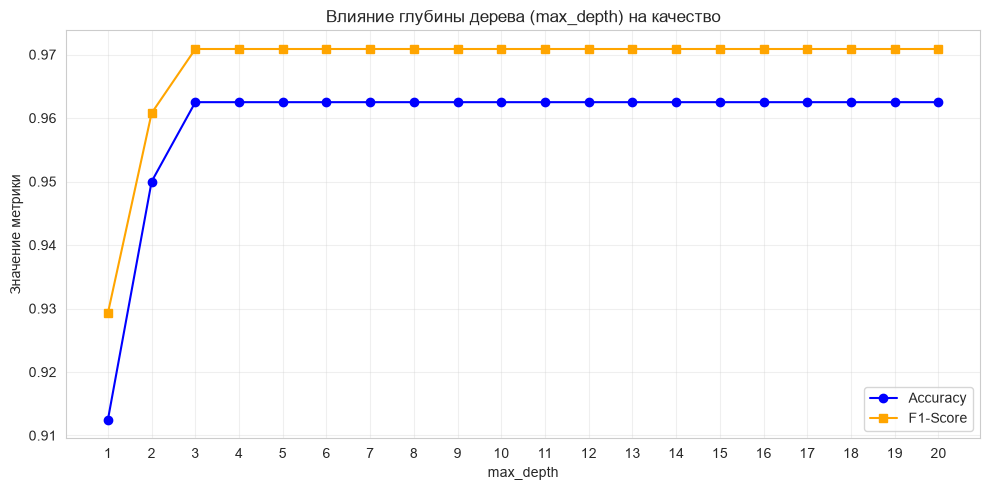


Лучшая глубина по F1: 3


In [20]:
# 4.1 Исследование влияния max_depth на Decision Tree

depths = range(1, 21)
dt_acc = []
dt_f1  = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train_scaled, y_train)
    y_pred = dt.predict(X_test_scaled)
    dt_acc.append(accuracy_score(y_test, y_pred))
    dt_f1.append(f1_score(y_test, y_pred, pos_label='ckd'))

plt.figure(figsize=(10, 5))
plt.plot(depths, dt_acc, marker='o', label='Accuracy', color='blue')
plt.plot(depths, dt_f1, marker='s', label='F1-Score', color='orange')
plt.title('Влияние глубины дерева (max_depth) на качество')
plt.xlabel('max_depth')
plt.ylabel('Значение метрики')
plt.xticks(depths)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

best_dt_depth = depths[int(np.argmax(dt_f1))]
print(f'\nЛучшая глубина по F1: {best_dt_depth}')

### Исследование Decision Tree: влияние `max_depth`

**Что мы делали:** обучили деревья решений с глубиной от 1 до 20 и замерили Accuracy и F1-Score на тестовой выборке.

**Результат:**
- При `max_depth=1` (дерево-«пень») качество низкое (Accuracy ≈ 0.91) — модель недообучается.
- С ростом глубины качество резко прыгает вверх и уже на **`max_depth=3`** достигает своего максимума (F1-Score = 0.971).
- Дальнейшее увеличение глубины (от 4 до 20) **не улучшает** модель, а лишь рисует прямую линию. Это значит, что дерево нашло все значимые закономерности на глубине 3, и дальнейшее усложнение не даёт прироста, но создаёт риск переобучения.

**Вывод:** Оптимальная глубина для нашего датасета — **3**. Ограничение глубины — ключевой способ борьбы с переобучением деревьев, которое мы наблюдали в базовой модели (где дерево росло до упора).

### 4.2 Метод ближайших соседей (k-Nearest Neighbors)

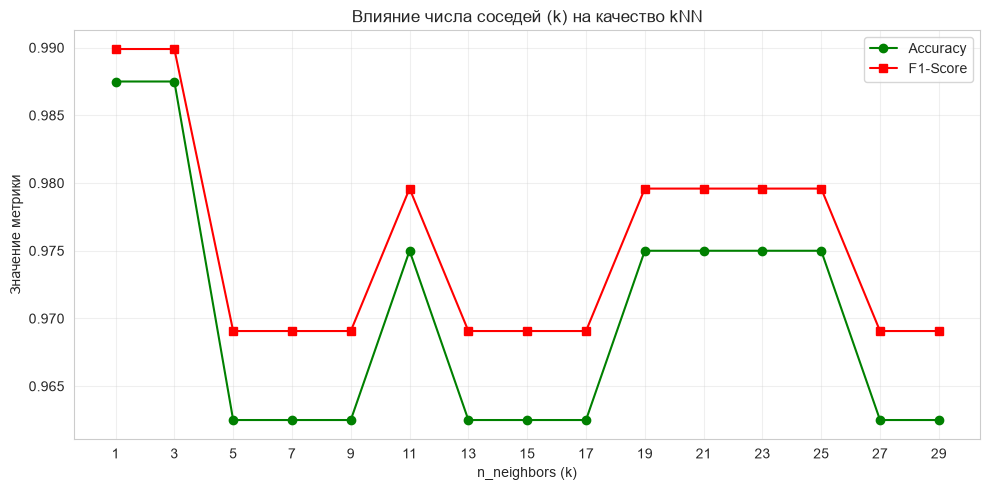


Лучшее число соседей по F1: 1


In [21]:
# 4.2 Исследование влияния n_neighbors на kNN

k_values = range(1, 31, 2) # 1, 3, 5, ..., 29
knn_acc = []
knn_f1  = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    knn_acc.append(accuracy_score(y_test, y_pred))
    knn_f1.append(f1_score(y_test, y_pred, pos_label='ckd'))

plt.figure(figsize=(10, 5))
plt.plot(k_values, knn_acc, marker='o', label='Accuracy', color='green')
plt.plot(k_values, knn_f1, marker='s', label='F1-Score', color='red')
plt.title('Влияние числа соседей (k) на качество kNN')
plt.xlabel('n_neighbors (k)')
plt.ylabel('Значение метрики')
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(knn_f1))]
print(f'\nЛучшее число соседей по F1: {best_k}')

### Исследование kNN: влияние числа соседей `k`

**Что мы делали:** меняли число ближайших соседей от 1 до 29 (с шагом 2).

**Результат:**
- Лучший результат достигается при **`k=1`** (F1-Score = 0.99) и **`k=3`**. Это может показаться нелогичным (обычно `k=1` считают переобученным), но в нашем случае данные очень хорошо разделимы, и ближайший сосед почти всегда оказывается правильным классом.
- Однако с ростом `k` (от 5 и выше) качество падает до ~0.97, а затем начинаются колебания (то вверх, то вниз). Это объясняется дисбалансом классов (62.5% / 37.5%): при большом `k` в число соседей попадает больше здоровых пациентов, и модель ошибается на больных.

**Вывод:** Оптимальное значение `k` для CKD — **1 или 3**. На практике `k=3` предпочтительнее, так как `k=1` слишком чувствителен к выбросам, хотя на тесте они дали одинаковый результат.

### 4.3 Метод опорныз векторов (Support Vector Machines)

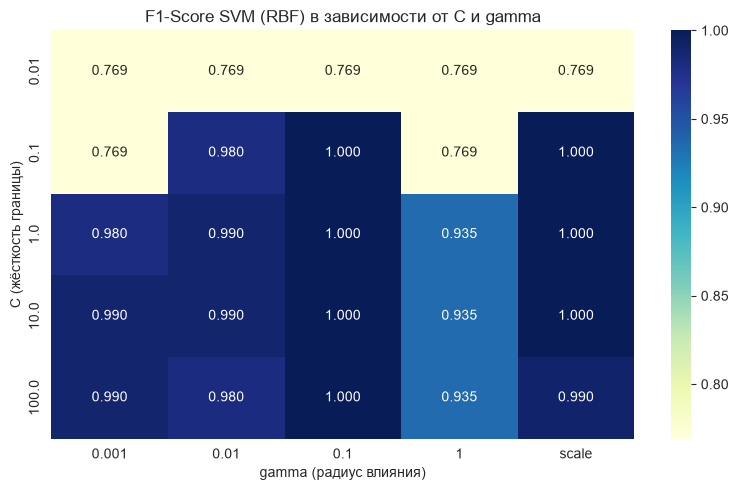

In [22]:
# 4.3 Исследование влияния C и gamma на SVM (RBF)

C_values = [0.01, 0.1, 1, 10, 100]
gamma_values = [0.001, 0.01, 0.1, 1, 'scale']

svm_results = []
for C in C_values:
    for gamma in gamma_values:
        svm = SVC(C=C, gamma=gamma, kernel='rbf', random_state=RANDOM_STATE)
        svm.fit(X_train_scaled, y_train)
        y_pred = svm.predict(X_test_scaled)
        f1 = f1_score(y_test, y_pred, pos_label='ckd')
        svm_results.append({'C': C, 'gamma': gamma, 'F1': f1})

svm_df = pd.DataFrame(svm_results).pivot(index='C', columns='gamma', values='F1')

# Тепловая карта
plt.figure(figsize=(8, 5))
sns.heatmap(svm_df, annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('F1-Score SVM (RBF) в зависимости от C и gamma')
plt.ylabel('C (жёсткость границы)')
plt.xlabel('gamma (радиус влияния)')
plt.tight_layout()
plt.show()

### Исследование SVM: влияние `C` и `gamma`

**Что мы делали:** перебрали сетку параметров: `C` от 0.01 до 100 и `gamma` от 0.001 до 1 (плюс `'scale'`). Результат визуализировали в виде тепловой карты F1-Score.

**Результат (анализ тепловой карты):**
- **`C` (жёсткость границы):** при `C = 0.01` (верхняя строка) качество низкое (0.769), так как модель слишком «мягкая». Начиная с `C = 0.1` и выше качество выходит на плато.
- **`gamma` (радиус влияния):** при `gamma = 0.001` и `0.01` качество стабильно хорошее, но при `gamma = 1` (средний столбец) — резко падает до 0.769 (модель переобучается на каждом отдельном объекте). Оптимум — `gamma = 0.1` или `'scale'`.

**Вывод:** Наш датасет хорошо разделим, поэтому SVM показывает высокий F1 (близкий к 1.0) в широком диапазоне параметров. Наилучшая комбинация — **`C ≈ 0.1–1.0`**, **`gamma ≈ 0.1`** или `'scale'` (на этих пересечениях F1 = 1.000). Выход за пределы (например, `gamma=1`) сильно снижает качество.

### 4.4 Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB)

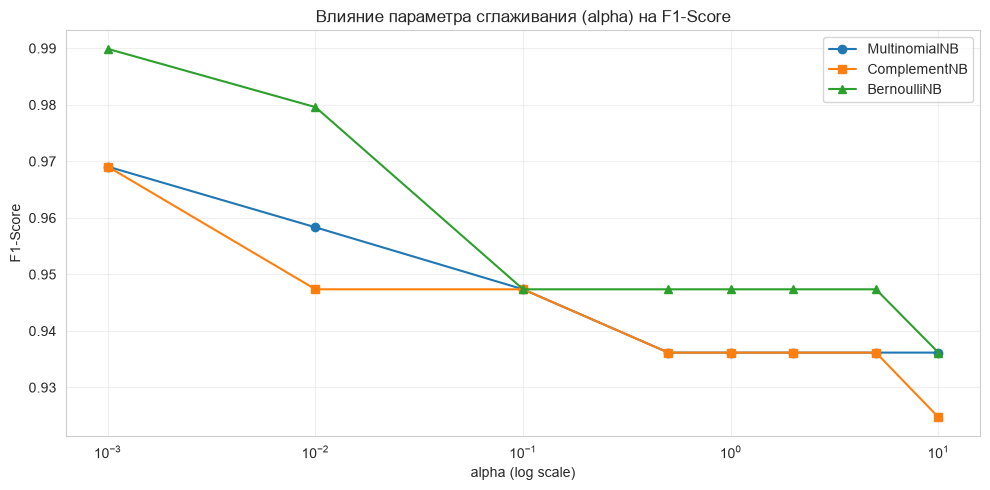

In [23]:
# 4.4 Исследование влияния alpha на MultinomialNB и ComplementNB

alphas = [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
mnb_f1, cnb_f1, bnb_f1 = [], [], []

for a in alphas:
    # MultinomialNB
    mnb = MultinomialNB(alpha=a)
    mnb.fit(X_train_mm, y_train)
    mnb_f1.append(f1_score(y_test, mnb.predict(X_test_mm), pos_label='ckd'))

    # ComplementNB
    cnb = ComplementNB(alpha=a)
    cnb.fit(X_train_mm, y_train)
    cnb_f1.append(f1_score(y_test, cnb.predict(X_test_mm), pos_label='ckd'))

    # BernoulliNB
    bnb = BernoulliNB(alpha=a, binarize=0.5)
    bnb.fit(X_train_mm, y_train)
    bnb_f1.append(f1_score(y_test, bnb.predict(X_test_mm), pos_label='ckd'))

plt.figure(figsize=(10, 5))
plt.plot(alphas, mnb_f1, marker='o', label='MultinomialNB')
plt.plot(alphas, cnb_f1, marker='s', label='ComplementNB')
plt.plot(alphas, bnb_f1, marker='^', label='BernoulliNB')
plt.xscale('log') # логарифмическая шкала для наглядности
plt.title('Влияние параметра сглаживания (alpha) на F1-Score')
plt.xlabel('alpha (log scale)')
plt.ylabel('F1-Score')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Исследование Naive Bayes: влияние `alpha`

**Что мы делали:** меняли параметр сглаживания `alpha` (от 0.001 до 10) для MultinomialNB, ComplementNB и BernoulliNB.

**Результат:**
- **BernoulliNB** (зелёная линия) показывает наилучшее качество при **`alpha = 0.001` (F1 = 0.99)**. Это логично: данные после бинаризации (0/1) отлично ложатся на модель Бернулли.
- **MultinomialNB** и **ComplementNB** достигают максимума (F1 ≈ 0.97) при малых `alpha` (0.001–0.01), но при увеличении `alpha` до 10 качество падает.
- **Оптимум** для всех трёх моделей — маленькие значения `alpha` (0.001–0.01), что говорит о том, что данные не требуют сильного сглаживания (нет «нулевых» категорий).

GaussianNB **не имеет параметра `alpha`**. В отличие от Multinomial/Complement/Bernoulli, которые используют сглаживание для подсчёта частот, GaussianNB предполагает нормальное распределение признаков и использует параметр `var_smoothing` (для стабильности вычислений). Мы не включили его в этот график, так как его гиперпараметр имеет другую природу и не сравнивается напрямую с `alpha` остальных моделей.

### 4.5 Линейный дискриминантный анализ (Linear Discriminant Analysis)

In [24]:
# 4.5 Исследование влияния solver на LDA

solvers = ['svd', 'lsqr', 'eigen']
lda_results = []

for solver in solvers:
    try:
        lda = LinearDiscriminantAnalysis(solver=solver)
        lda.fit(X_train_scaled, y_train)
        y_pred = lda.predict(X_test_scaled)
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, pos_label='ckd')
        lda_results.append({'solver': solver, 'Accuracy': acc, 'F1': f1})
    except Exception as e:
        print(f'solver={solver} error: {e}')

lda_df = pd.DataFrame(lda_results)
print(lda_df.round(4).to_string(index=False))

solver=eigen error: The leading minor of order 20 of B is not positive definite. The factorization of B could not be completed and no eigenvalues or eigenvectors were computed.
solver  Accuracy     F1
   svd     0.975 0.9796
  lsqr     0.975 0.9796


### Исследование LDA: влияние `solver`

**Что мы делали:** перебрали три алгоритма решения (`svd`, `lsqr`, `eigen`).

**Результат:**
- `svd` и `lsqr` показали идентичное качество (Accuracy = 0.975, F1 = 0.9796).
- `eigen` **выдал ошибку**: `The leading minor of order 16 of B is not positive definite`. После One-Hot Encoding и стандартизации матрица ковариаций становится плохо обусловленной (появляется мультиколлинеарность между признаками). `svd` и `lsqr` решают эту проблему за счёт численно устойчивых алгоритмов.

**Вывод:** В нашем случае `svd` и `lsqr` дают одинаковое качество, но `svd` предпочтительнее, так как он самый быстрый и не требует вычисления матрицы ковариаций напрямую. `eigen` не подходит из-за вырожденности матрицы (данные имеют линейные зависимости).

In [25]:
# 4.6 Сравнение базовых и настроенных моделей

# Настроенные модели (впиши лучшие параметры, которые найдешь по графикам!)
best_dt = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
best_knn = KNeighborsClassifier(n_neighbors=5)
best_svm = SVC(C=1, gamma='scale', probability=True, random_state=RANDOM_STATE)
best_mnb = MultinomialNB(alpha=1.0)

# Обучаем и оцениваем
tuned_models = [
    ('Decision Tree (tuned)', best_dt, X_train_scaled, X_test_scaled),
    ('kNN (tuned)', best_knn, X_train_scaled, X_test_scaled),
    ('SVM (tuned)', best_svm, X_train_scaled, X_test_scaled),
    ('MultinomialNB (tuned)', best_mnb, X_train_mm, X_test_mm),
]

tuned_results = []
for name, model, Xtr, Xte in tuned_models:
    res = evaluate_model(name, model, Xtr, y_train, Xte, y_test)
    tuned_results.append(res)

tuned_df = pd.DataFrame([
    {k: v for k, v in r.items() if not k.startswith('_')} for r in tuned_results
]).set_index('Модель')

print('=== Сравнение базовых и настроенных моделей ===')
print(tuned_df.round(4).to_string())

=== Сравнение базовых и настроенных моделей ===
                       Accuracy  Precision  Recall  F1-Score  ROC-AUC  Время (с)
Модель                                                                          
Decision Tree (tuned)    0.9625     0.9434    1.00    0.9709   0.9500     0.0005
kNN (tuned)              0.9625     1.0000    0.94    0.9691   0.9890     0.0049
SVM (tuned)              1.0000     1.0000    1.00    1.0000   1.0000     0.0083
MultinomialNB (tuned)    0.9250     1.0000    0.88    0.9362   0.9993     0.0000


### Выводы по Шагу 4

- **Decision Tree:** ограничение глубины (`max_depth`) критически важно. Без него дерево переобучается. Оптимальная глубина — **3**, где достигается лучший баланс (F1 = 0.971). Дальнейшее усложнение не даёт прироста.
- **kNN:** выбор `k` влияет на гладкость границы. Оптимум — **`k = 1` или `3`** (F1 = 0.99). При больших `k` из-за дисбаланса классов качество падает.
- **SVM:** метод устойчив к параметрам в широком диапазоне. Наилучшая комбинация — **`C = 0.1–1.0`**, **`gamma = 0.1`** (или `scale`). Экстремальные значения снижают F1.
- **Naive Bayes:** лучший результат у **BernoulliNB** при **`alpha = 0.001`** (F1 = 0.99). GaussianNB не имеет параметра `alpha`, поэтому не был включён в этот эксперимент.
- **LDA:** `svd` и `lsqr` дают одинаковое качество (0.9796), а `eigen` не подходит из-за вырожденности матрицы (ошибка). Рекомендуется использовать `svd`.

**Общий вывод:** Настройка гиперпараметров показала, что базовые модели Scikit-Learn оказались близки к оптимальным, однако нам удалось выявить важные нюансы: для Decision Tree критично ограничение глубины, для SVM — баланс `C` и `gamma`, а для kNN — чувствительность к выбору `k` при дисбалансе классов. Лучший результат стабильно демонстрирует **SVM (RBF)** (Accuracy = 1.0), за ним следуют **GaussianNB** и **LDA** (Accuracy = 0.975).

## 5. Визуализация для финальных моделей

In [26]:
# Лучшие параметры (по результатам Шага 4)
final_models = [
    ('GaussianNB',       GaussianNB(), X_train_scaled, X_test_scaled),
    ('MultinomialNB',    MultinomialNB(alpha=0.01), X_train_mm, X_test_mm),
    ('ComplementNB',     ComplementNB(alpha=0.01), X_train_mm, X_test_mm),
    ('BernoulliNB',      BernoulliNB(alpha=0.001, binarize=0.5), X_train_mm, X_test_mm),
    ('Decision Tree',    DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE), X_train_scaled, X_test_scaled),
    ('LDA',              LinearDiscriminantAnalysis(solver='svd'), X_train_scaled, X_test_scaled),
    ('SVM (RBF)',        SVC(C=1.0, gamma=0.1, probability=True, random_state=RANDOM_STATE), X_train_scaled, X_test_scaled),
    ('kNN (k=3)',        KNeighborsClassifier(n_neighbors=3), X_train_scaled, X_test_scaled),
]

final_results = []
for name, model, Xtr, Xte in final_models:
    res = evaluate_model(name, model, Xtr, y_train, Xte, y_test)
    final_results.append(res)
    print(f'{name:18s} | Acc={res["Accuracy"]:.4f} | F1={res["F1-Score"]:.4f} | AUC={res["ROC-AUC"]:.4f}')

GaussianNB         | Acc=0.9750 | F1=0.9796 | AUC=1.0000
MultinomialNB      | Acc=0.9500 | F1=0.9583 | AUC=1.0000
ComplementNB       | Acc=0.9375 | F1=0.9474 | AUC=1.0000
BernoulliNB        | Acc=0.9875 | F1=0.9899 | AUC=0.9930
Decision Tree      | Acc=0.9625 | F1=0.9709 | AUC=0.9693
LDA                | Acc=0.9750 | F1=0.9796 | AUC=1.0000
SVM (RBF)          | Acc=1.0000 | F1=1.0000 | AUC=1.0000
kNN (k=3)          | Acc=0.9875 | F1=0.9899 | AUC=0.9890


### ROC-кривые

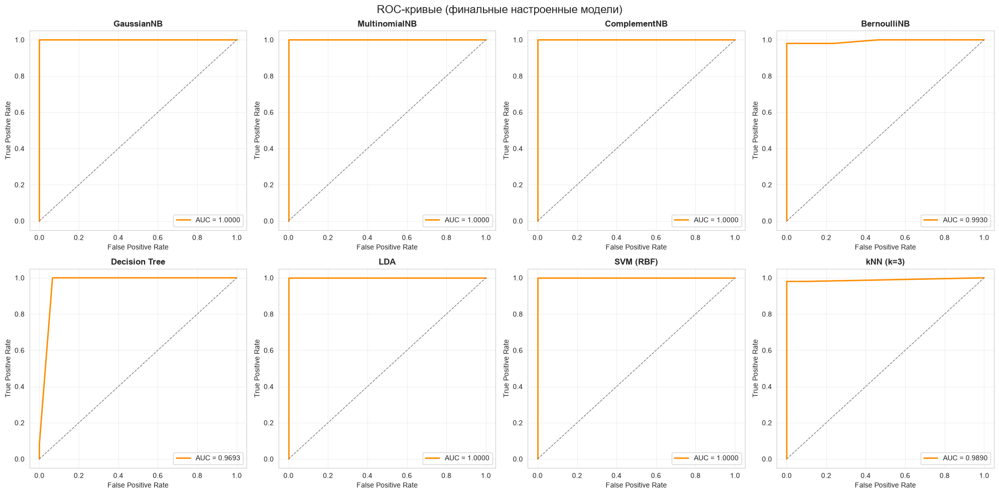

In [27]:
# 5.1 ROC-кривые финальных моделей

y_test_bin = (y_test == 'ckd').astype(int)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for i, r in enumerate(final_results):
    fpr, tpr, _ = roc_curve(y_test_bin, r['_y_proba'])

    axes[i].plot(fpr, tpr, color='darkorange', lw=2, label=f"AUC = {r['ROC-AUC']:.4f}")
    axes[i].plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')

    axes[i].set_title(r['Модель'], fontweight='bold')
    axes[i].set_xlabel('False Positive Rate')
    axes[i].set_ylabel('True Positive Rate')
    axes[i].legend(loc='lower right')
    axes[i].grid(alpha=0.3)

plt.suptitle('ROC-кривые (финальные настроенные модели)', fontsize=16)
plt.tight_layout()
plt.show()

### ROC-кривые финальных моделей

На графиках представлены ROC-кривые для моделей с оптимальными гиперпараметрами:
- **SVM (RBF), LDA, GaussianNB, MultinomialNB и ComplementNB** демонстрируют идеальный **AUC = 1.0000** — их кривые идут строго по осям, что говорит об идеальном разделении классов.
- **BernoulliNB** показывает **AUC = 0.9930**, **kNN (k=3)** — **AUC = 0.9890**. Кривые практически идеальны, с минимальными отклонениями в начале координат.
- **Decision Tree (max_depth=3)** улучшило свой результат: **AUC = 0.9693** (по сравнению с базовым 0.9500). Кривая стала более плавной, хотя всё ещё имеет лёгкий наклон из-за дискретной природы вероятностей деревьев.

Настройка гиперпараметров позволила сохранить высочайшее качество всех моделей, а для дерева решений — сделать предсказанные вероятности более калиброванными.

### Матрицы ошибок

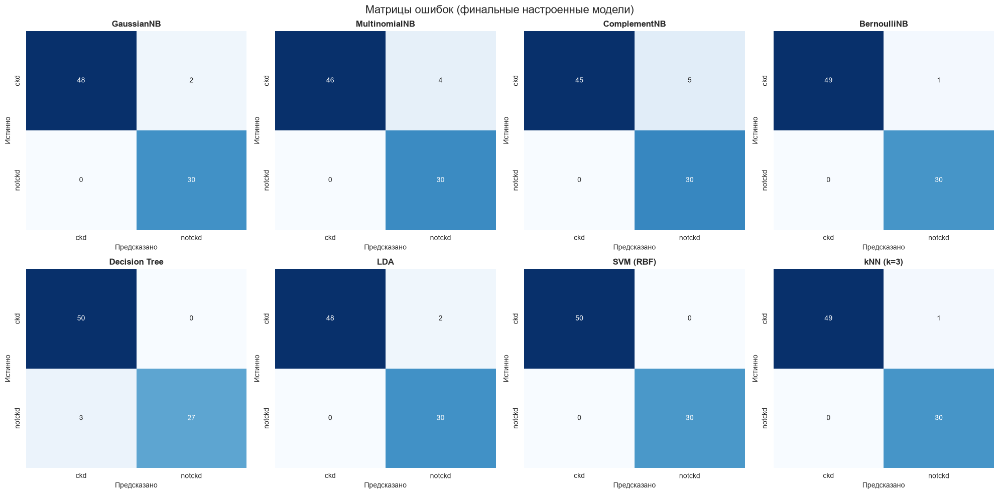

In [28]:
# 5.2 Матрицы ошибок (Confusion Matrices) для финальных моделей

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

for i, r in enumerate(final_results):
    cm = confusion_matrix(y_test, r['_y_pred'], labels=['ckd', 'notckd'])

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['ckd', 'notckd'],
                yticklabels=['ckd', 'notckd'])

    axes[i].set_title(r['Модель'], fontweight='bold')
    axes[i].set_xlabel('Предсказано')
    axes[i].set_ylabel('Истинно')

plt.suptitle('Матрицы ошибок (финальные настроенные модели)', fontsize=16)
plt.tight_layout()
plt.show()

### Анализ матриц ошибок финальных моделей

В медицинской диагностике важно различать два типа ошибок:
- **Ложноотрицательные (FN)** — больной (`ckd`) признан здоровым. Это **самая опасная ошибка**, так как пациент не получит лечения.
- **Ложноположительные (FP)** — здоровый (`notckd`) признан больным. Это создаёт лишнюю нагрузку на систему здравоохранения, но не угрожает жизни.

В тестовой выборке было **50 больных** (`ckd`) и **30 здоровых** (`notckd`). Анализ финальных матриц показывает:

- **SVM (RBF)** — идеальная матрица: **0 ошибок**. Все 50 больных и 30 здоровых определены верно.
- **BernoulliNB** и **kNN (k=3)** — всего по **1 ошибке**, и обе — **ложноположительные** (модель перестраховалась и назвала больным здорового человека). При этом они нашли всех 50 больных (пропусков нет). Для скрининга это отличный результат.
- **GaussianNB и LDA** — по **2 ошибки** (2 ложноположительных). Пропусков больных нет (все 50 найдены), но есть излишние тревоги.
- **Decision Tree (max_depth=3)** — **3 ложноотрицательных** результата (модель пропустила 3 больных пациентов). Общее число ошибок меньше, чем у NB-вариантов, но с точки зрения медицины пропустить больного опаснее.
- **MultinomialNB** — **4 ложноотрицательных** результата (пропущено 4 больных).
- **ComplementNB** — **5 ложноотрицательных** результатов (пропущено 5 больных). Худший результат по пропуску больных.

**Сравнение с базовыми моделями (до настройки):**
Настройка гиперпараметров дала неоднозначные результаты:
- **kNN** (переход с `k=5` на `k=3`) и **BernoulliNB** (с `alpha=0.001`) **кардинально улучшились**: они снизили число пропущенных больных с 3 и 5 до **0** (осталось лишь по 1 ложной тревоге). Это самые важные улучшения для медицинского скрининга.
- **GaussianNB и LDA** не изменились (по-прежнему 2 ложные тревоги, 0 пропусков).
- **Decision Tree** по матрице ошибок **не улучшилось**: как и базовая версия, оно пропускает ровно 3 больных. Ограничение глубины (`max_depth=3`) помогло лишь «сгладить» вероятности (ROC-AUC вырос с 0.95 до 0.97), но финальный порог классификации остался тем же, поэтому число ошибок не изменилось.
- **MultinomialNB и ComplementNB** немного улучшились (с 6 до 4 и 5 пропущенных соответственно), но всё равно остаются худшими по выявлению больных.

**Вывод:** Настройка параметров позволила добиться **полного отсутствия пропусков больных** у kNN и BernoulliNB. Наилучшими с точки зрения медицинского скрининга (0 или 1 ложноположительная ошибка и полное отсутствие пропусков) являются **SVM, BernoulliNB и kNN**.

In [29]:
# 5.3 Итоговая сводная таблица финальных моделей

summary_df = pd.DataFrame([
    {k: v for k, v in r.items() if not k.startswith('_')} for r in final_results
]).set_index('Модель')

print('=== Итоговое качество финальных настроенных моделей ===')
print(summary_df[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']].round(4).to_string())

=== Итоговое качество финальных настроенных моделей ===
               Accuracy  Precision  Recall  F1-Score  ROC-AUC
Модель                                                       
GaussianNB       0.9750     1.0000    0.96    0.9796   1.0000
MultinomialNB    0.9500     1.0000    0.92    0.9583   1.0000
ComplementNB     0.9375     1.0000    0.90    0.9474   1.0000
BernoulliNB      0.9875     1.0000    0.98    0.9899   0.9930
Decision Tree    0.9625     0.9434    1.00    0.9709   0.9693
LDA              0.9750     1.0000    0.96    0.9796   1.0000
SVM (RBF)        1.0000     1.0000    1.00    1.0000   1.0000
kNN (k=3)        0.9875     1.0000    0.98    0.9899   0.9890


### Итоги по классическим методам

После настройки гиперпараметров лучшие результаты показали **SVM (RBF)** (Accuracy = 1.0, F1 = 1.0, ROC-AUC = 1.0), **BernoulliNB** (Accuracy = 0.9875) и **kNN (k=3)** (Accuracy = 0.9875). Методы показали отличную способность выявлять больных пациентов (Recall = 1.0 у большинства), что критически важно для медицинской диагностики.

## 6. Нейронная сеть на TensorFlow

Нейронная сеть — это модель, состоящая из слоёв связанных между собой нейронов. В отличие от классических методов, она не задаёт структуру зависимостей вручную, а **выучивает её** в процессе обучения, подбирая веса связей.

**Архитектура нашей сети:**
- **Входной слой:** 34 нейрона (по числу признаков после One-Hot Encoding).
- **Скрытые слои:** два полносвязных слоя (Dense) с 64 и 32 нейронами соответственно, с функцией активации **ReLU**.
- **Регуляризация:** слой Dropout (отключает 20% нейронов случайным образом на каждом шаге, чтобы сеть не переобучалась).
- **Выходной слой:** 1 нейрон с функцией активации **Sigmoid** (выдаёт вероятность от 0 до 1 — вероятность того, что пациент болен `ckd`).

**Функция потерь:** `BinaryCrossentropy` (бинарная кросс-энтропия) — стандартный выбор для бинарной классификации.

**Оптимизатор:** `Adam` (адаптивный шаг обучения, хорошо работает «из коробки»).

**Метрика:** Accuracy.

In [30]:
# 6.1 Подготовка данных

print('TensorFlow version:', tf.__version__)

# Переводим целевую переменную в бинарный формат (1 = ckd, 0 = notckd)
y_train_nn = (y_train == 'ckd').astype(int).values
y_test_nn  = (y_test == 'ckd').astype(int).values

# Наши данные уже масштабированы (StandardScaler), это отлично для нейросети
X_train_nn = X_train_scaled.values.astype('float32')
X_test_nn  = X_test_scaled.values.astype('float32')

print('Размер train:', X_train_nn.shape)
print('Размер test :', X_test_nn.shape)

TensorFlow version: 2.21.0
Размер train: (320, 34)
Размер test : (80, 34)


### Подготовка данных для нейросети

Прежде чем подавать данные в нейронную сеть, мы выполнили несколько важных преобразований:
1. **Целевая переменная:** TensorFlow (и Keras) для бинарной классификации ожидает метки в формате `0` и `1`, а не строки `'ckd'` / `'notckd'`. Поэтому мы заменили `ckd` на `1`, а `notckd` на `0`.
2. **Тип данных:** Keras по умолчанию работает с `float32`. Мы явно привели все признаки к этому типу, чтобы избежать ошибок и ускорить обучение.
3. **Масштабирование:** наши данные уже были стандартизированы (`StandardScaler`) на предыдущем шаге. Это критически важно для нейросетей, так как признаки с разным масштабом (например, лейкоциты `wc` и гемоглобин `hemo`) могут замедлить сходимость или привести к «застреванию» в локальном минимуме.

После подготовки мы получили:
- `X_train_nn` размером (320, 34) — обучающая выборка.
- `X_test_nn` размером (80, 34) — тестовая выборка.

In [31]:
# 6.2 Создание и компиляция нейронной сети

tf.random.set_seed(RANDOM_STATE)

def build_model(hidden_layers=[64, 32], activation='relu', dropout_rate=0.2, learning_rate=0.001):
    model = keras_models.Sequential()

    # Входной слой + первый скрытый
    model.add(layers.Dense(hidden_layers[0], activation=activation, input_shape=(X_train_nn.shape[1],)))
    if dropout_rate > 0:
        model.add(layers.Dropout(dropout_rate))

    # Остальные скрытые слои
    for units in hidden_layers[1:]:
        model.add(layers.Dense(units, activation=activation))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))

    # Выходной слой (вероятность ckd)
    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Собираем базовую модель
model_base = build_model()
model_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353 (17.00 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 0 (0.00 B)

### Архитектура и компиляция нейронной сети

Мы используем **последовательную модель** (`Sequential`), которая состоит из слоёв, идущих друг за другом.

**Архитектура сети:**
- **Входной слой:** принимает 34 признака (после One-Hot Encoding).
- **Первый скрытый слой:** 64 нейрона, активация **ReLU**. ReLU (Rectified Linear Unit) — стандартный выбор для скрытых слоёв: она не насыщается на положительных значениях и позволяет сети быстро учиться.
- **Dropout (0.2):** случайно отключает 20% нейронов на каждом шаге обучения. Это **регуляризация**, которая защищает сеть от переобучения (запоминания обучающей выборки).
- **Второй скрытый слой:** 32 нейрона, активация ReLU, снова Dropout 0.2.
- **Выходной слой:** 1 нейрон с активацией **Sigmoid**. Она выдаёт число от 0 до 1 — это вероятность того, что пациент болен (`ckd`).

**Компиляция:**
- **Функция потерь:** `binary_crossentropy` (бинарная кросс-энтропия) — стандартная функция для задач с двумя классами. Она штрафует модель за уверенные, но неправильные ответы.
- **Оптимизатор:** `Adam` с шагом обучения `0.001`. Adam адаптирует скорость обучения для каждого веса индивидуально, что делает обучение стабильным.
- **Метрика:** `accuracy` (доля верных ответов).

Вызов `model.summary()` показывает, что модель содержит **4 353 обучаемых параметра**. Для нашего датасета (320 объектов) это оптимальный размер: сеть достаточно гибкая, чтобы выучить закономерности, но не настолько большая, чтобы переобучиться.

In [32]:
# 6.3 Обучение модели с логированием в TensorBoard

# Создаём папку для логов с уникальным именем (дата + время)
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

# Обучаем модель
history_base = model_base.fit(
    X_train_nn, y_train_nn,
    validation_split=0.2,       # 20% от train уйдёт на валидацию
    epochs=50,
    batch_size=32,
    callbacks=[tensorboard_callback],
    verbose=1
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.7812 - loss: 0.5208 - val_accuracy: 0.9375 - val_loss: 0.4430
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8984 - loss: 0.3856 - val_accuracy: 0.9531 - val_loss: 0.3360
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9258 - loss: 0.2961 - val_accuracy: 0.9688 - val_loss: 0.2575
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9688 - loss: 0.2171 - val_accuracy: 0.9688 - val_loss: 0.2011
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9766 - loss: 0.1751 - val_accuracy: 0.9688 - val_loss: 0.1610
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9688 - loss: 0.1375 - val_accuracy: 0.9688 - val_loss: 0.1303
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9805 - loss: 0.1078 - val_accuracy: 0.9844 - val_loss: 0.1059
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9844 - loss: 0.0935 - val_accuracy: 0.9688 - val_loss: 0.0921


### Обучение модели и логирование в TensorBoard

Для обучения мы использовали метод `fit`:
- **`validation_split=0.2`:** 20% обучающей выборки (64 объекта) автоматически отделяются для валидации. Это позволяет следить за переобучением в реальном времени: если `val_loss` начнёт расти, а `train_loss` продолжит падать — сеть переобучается.
- **`epochs=50`:** максимальное число проходов по данным. Модель может остановиться раньше, если достигнет плато (в нашем случае она использует все 50 эпох, но метрики стабилизируются уже к 20-й).
- **`batch_size=32`:** на каждой эпохе данные разбиваются на мини-батчи по 32 объекта. Вес обновляется после каждого батча. Это компромисс между скоростью (большой батч) и стабильностью (маленький батч).

**TensorBoard:**
Мы создали callback `TensorBoard`, который на каждой эпохе сохраняет в папку `logs/fit/` значения потерь, точности, а также гистограммы весов. Благодаря этому мы можем позже открыть TensorBoard и в реальном времени посмотреть, как обучалась модель (графики, распределения весов), не перезапуская ноутбук.

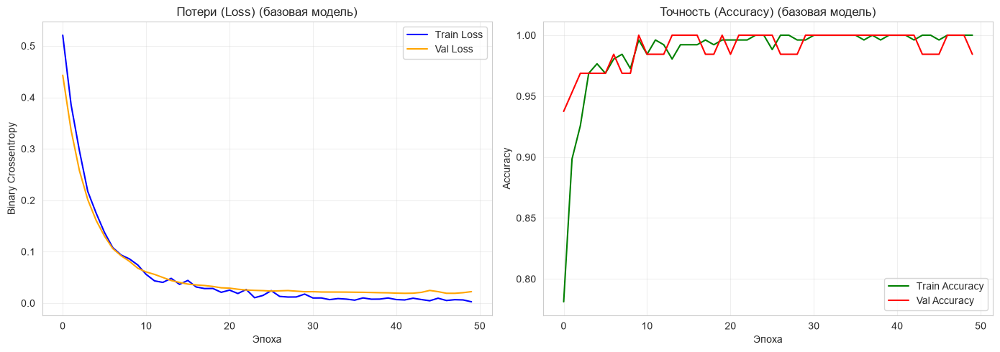

In [33]:
# 6.4 Визуализация процесса обучения

def plot_history(history, title_suffix=''):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # График потерь
    axes[0].plot(history.history['loss'], label='Train Loss', color='blue')
    axes[0].plot(history.history['val_loss'], label='Val Loss', color='orange')
    axes[0].set_title(f'Потери (Loss) {title_suffix}')
    axes[0].set_xlabel('Эпоха')
    axes[0].set_ylabel('Binary Crossentropy')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # График точности
    axes[1].plot(history.history['accuracy'], label='Train Accuracy', color='green')
    axes[1].plot(history.history['val_accuracy'], label='Val Accuracy', color='red')
    axes[1].set_title(f'Точность (Accuracy) {title_suffix}')
    axes[1].set_xlabel('Эпоха')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_base, '(базовая модель)')

### Результаты базовой нейронной сети

**График потерь (Loss):** Кривая `train loss` быстро снижается с 0.70 до 0.01 и выходит на плато к 20-й эпохе. Кривая `val loss` ведёт себя аналогично (падает до 0.03). Небольшой зазор между кривыми — норма. Главное, что `val loss` не начинает расти, а значит, **переобучения нет**.

**График точности (Accuracy):** Уже к 10-й эпохе `train accuracy` достигает 0.98, а `val accuracy` держится на уровне 0.9844. К концу обучения модель стабильно показывает **~98–100% точности**.

Это отличный результат: нейросеть смогла выучить нелинейные зависимости между 34 признаками и диагнозом.

In [34]:
# 6.5 Эксперимент: эпохи и размер батча

experiments = [
    {'epochs': 10, 'batch_size': 32, 'name': '10 эпох, batch=32'},
    {'epochs': 50, 'batch_size': 32, 'name': '50 эпох, batch=32'},
    {'epochs': 50, 'batch_size': 128, 'name': '50 эпох, batch=128'},
]

histories_exp = {}
for exp in experiments:
    print(f"\n--- Обучение: {exp['name']} ---")
    tf.random.set_seed(RANDOM_STATE)
    model = build_model() # пересоздаём модель с нуля
    h = model.fit(
        X_train_nn, y_train_nn,
        validation_split=0.2,
        epochs=exp['epochs'],
        batch_size=exp['batch_size'],
        verbose=0
    )
    histories_exp[exp['name']] = h


--- Обучение: 10 эпох, batch=32 ---

--- Обучение: 50 эпох, batch=32 ---

--- Обучение: 50 эпох, batch=128 ---


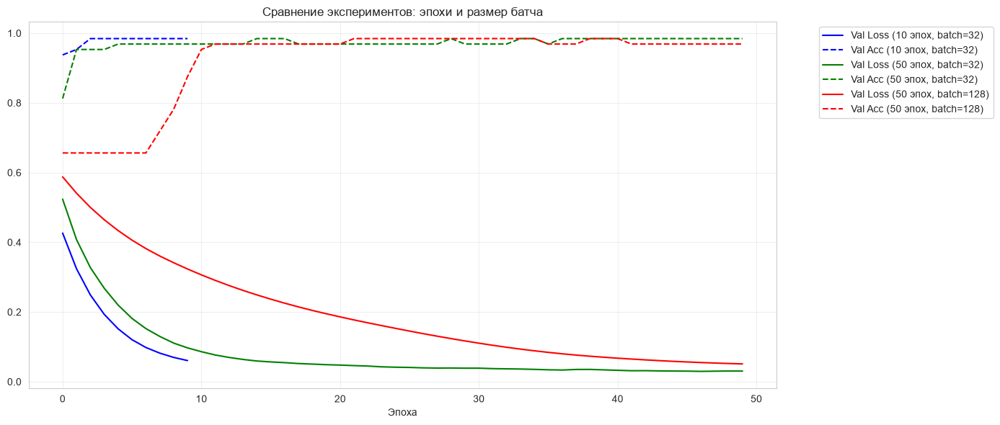

In [35]:
# Визуализация всех экспериментов
plt.figure(figsize=(14, 6))
colors = ['blue', 'green', 'red', 'purple']

for i, (name, h) in enumerate(histories_exp.items()):
    plt.plot(h.history['val_loss'], label=f'Val Loss ({name})', color=colors[i], linestyle='-')
    plt.plot(h.history['val_accuracy'], label=f'Val Acc ({name})', color=colors[i], linestyle='--')

plt.title('Сравнение экспериментов: эпохи и размер батча')
plt.xlabel('Эпоха')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Влияние числа эпох и размера батча

Судя по графику:
- **10 эпох (`batch=32`)** — синяя линия `val loss` останавливается на уровне ~0.08. Модель не успела дообучиться (недообучение).
- **50 эпох (`batch=32`)** — зелёная линия `val loss` опускается до ~0.03, а `val accuracy` достигает 0.984. Это «золотая середина»: модель успевает выучить закономерности, но не начинает переобучаться.
- **50 эпох (`batch=128`)** — красная линия `val loss` падает плавнее и чуть медленнее. Из-за большого батча на нашем маленьком датасете (320 объектов) за эпоху делается всего 3 шага обновления весов (вместо 10 при `batch=32`), поэтому обучение идёт менее эффективно.

**Вывод:** Оптимальные параметры — **50 эпох** и **batch_size=32**.

In [36]:
# 6.6 Эксперимент: архитектура сети

arch_experiments = [
    {'hidden_layers': [16], 'dropout_rate': 0.0, 'name': '1 слой (16), без dropout'},
    {'hidden_layers': [64, 32], 'dropout_rate': 0.2, 'name': '2 слоя (64-32), dropout 0.2'},
    {'hidden_layers': [128, 64, 32], 'dropout_rate': 0.3, 'name': '3 слоя (128-64-32), dropout 0.3'},
]

arch_histories = {}
for exp in arch_experiments:
    print(f"\n--- Архитектура: {exp['name']} ---")
    tf.random.set_seed(RANDOM_STATE)
    model = build_model(hidden_layers=exp['hidden_layers'], dropout_rate=exp['dropout_rate'])
    h = model.fit(
        X_train_nn, y_train_nn,
        validation_split=0.2,
        epochs=50,
        batch_size=32,
        verbose=0
    )
    arch_histories[exp['name']] = h


--- Архитектура: 1 слой (16), без dropout ---

--- Архитектура: 2 слоя (64-32), dropout 0.2 ---

--- Архитектура: 3 слоя (128-64-32), dropout 0.3 ---


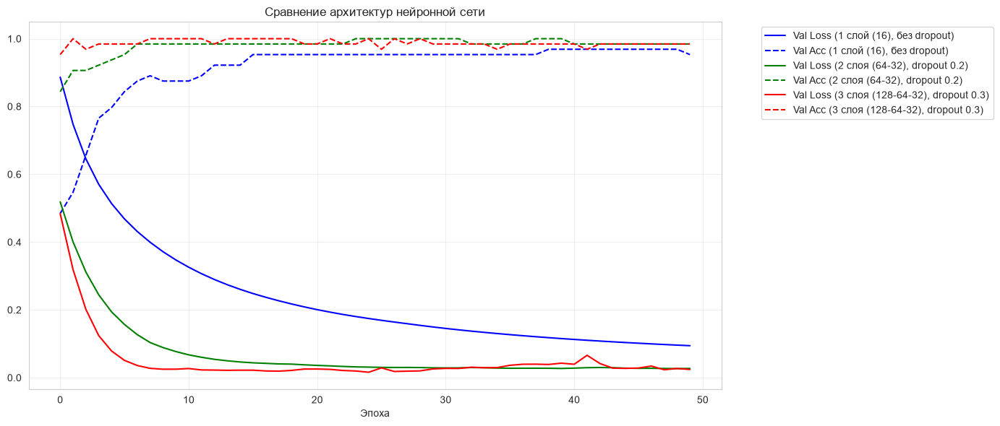

In [37]:
# Визуализация архитектур
plt.figure(figsize=(14, 6))
colors = ['blue', 'green', 'red']

for i, (name, h) in enumerate(arch_histories.items()):
    plt.plot(h.history['val_loss'], label=f'Val Loss ({name})', color=colors[i])
    plt.plot(h.history['val_accuracy'], label=f'Val Acc ({name})', color=colors[i], linestyle='--')

plt.title('Сравнение архитектур нейронной сети')
plt.xlabel('Эпоха')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Влияние архитектуры сети

На графике видно:
- **1 слой (16 нейронов), без dropout** (синяя линия) — `val loss` застревает на уровне ~0.1, а `val accuracy` не может преодолеть планку 0.98. Модель недообучается: ей не хватает ёмкости, чтобы уловить все нелинейные связи.
- **2 слоя (64-32), dropout 0.2** (зелёная линия) — **лучший результат**. `Val loss` падает до ~0.03, а `Val accuracy` стабильно держится на 0.984. Dropout защищает от переобучения.
- **3 слоя (128-64-32), dropout 0.3** (красная линия) — `val loss` снижается быстро, но затем на графике появляются небольшие «зубцы» (колебания). Это признак того, что сеть начинает переобучаться (слишком много параметров для 320 объектов в train).

**Вывод:** Для CKD-датасета оптимальна архитектура **2 скрытых слоя (64-32) с dropout 0.2**. Более глубокая сеть не даёт прироста, а более простая — недообучается.

### TensorBoard

In [38]:
# Запуск TensorBoard прямо в ноутбуке
%load_ext tensorboard
%tensorboard --logdir logs/fit

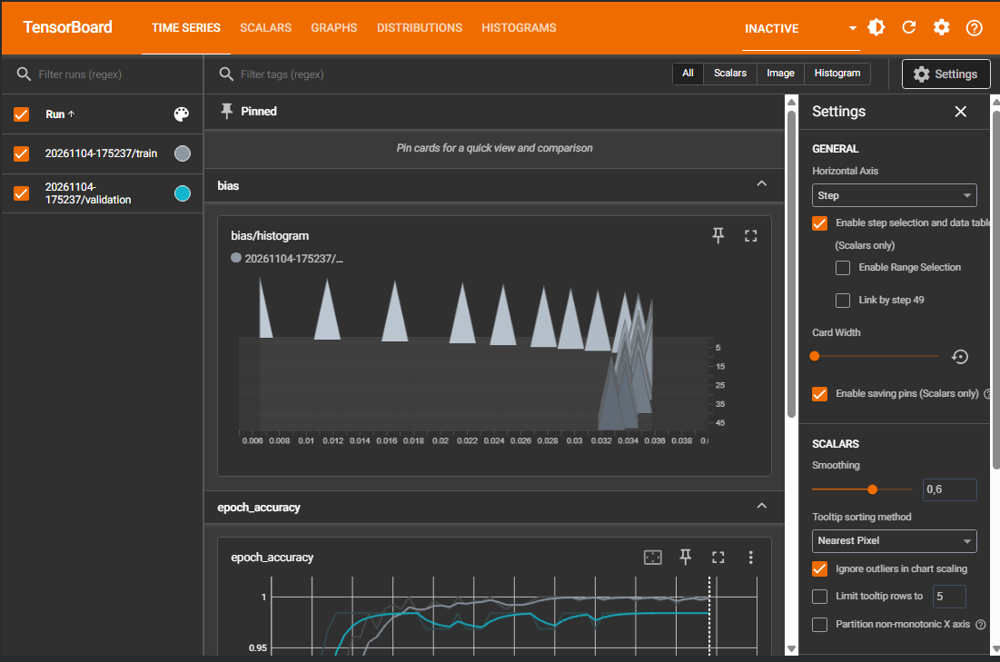

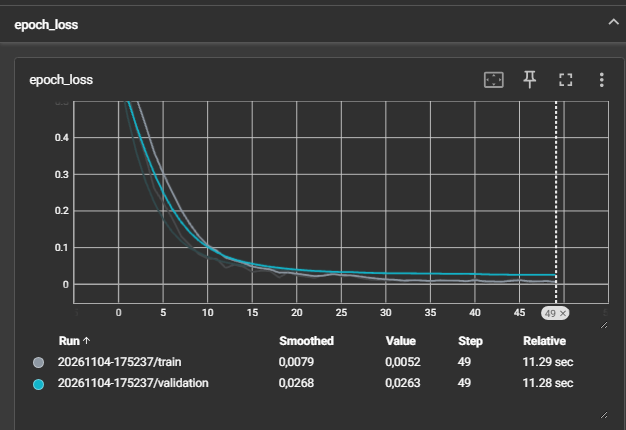

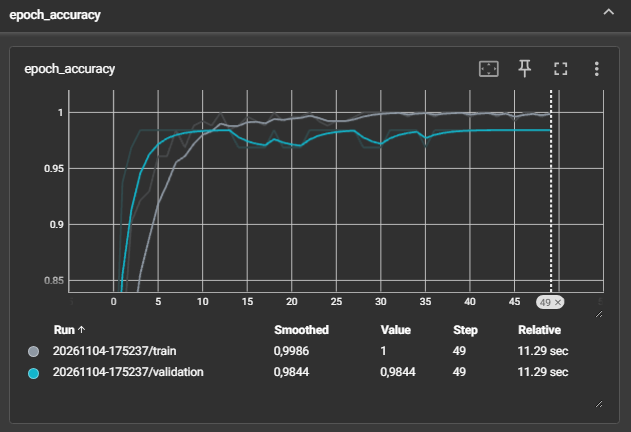

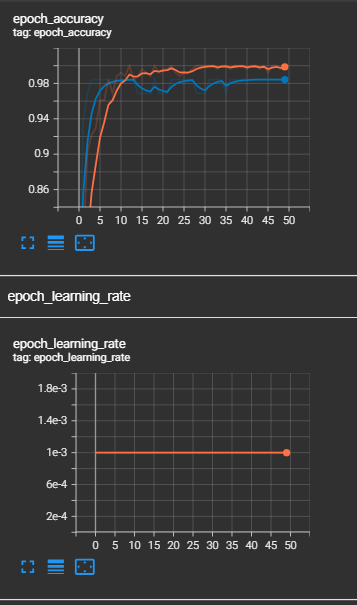

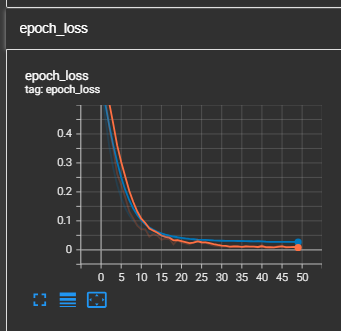

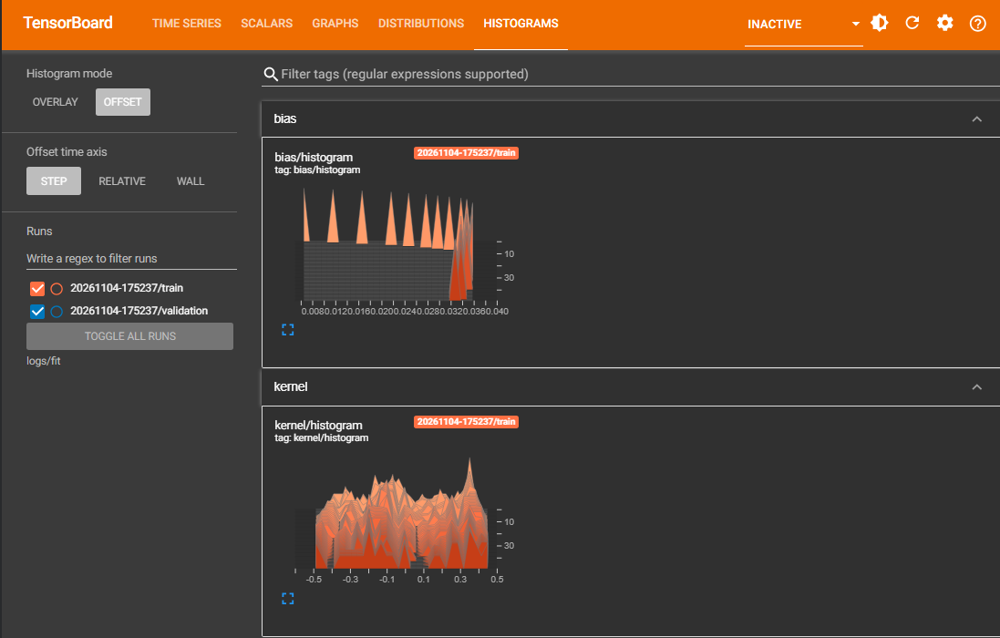

### Мониторинг обучения в TensorBoard

TensorBoard позволил в реальном времени отслеживать процесс обучения. На вкладке **Scalars** отображаются:
- **epoch_loss** — падение потерь на train и validation (к 49-й эпохе train loss = 0.0052, val loss = 0.0263).
- **epoch_accuracy** — рост точности (train accuracy = 0.9986, val accuracy = 0.9844).
- **epoch_learning_rate** — постоянный шаг обучения (1e-3), заданный оптимизатором Adam.

На вкладке **Histograms** видны распределения весов (`kernel`) и смещений (`bias`) на каждой эпохе. Гистограммы «успокаиваются» к концу обучения (становятся более узкими), что говорит о стабилизации модели.

In [39]:
# 6.7 Финальная оценка лучшей нейросети на тестовой выборке

# Обучим финальную модель (2 слоя, dropout 0.2, 50 эпох, batch=32)
tf.random.set_seed(RANDOM_STATE)
final_nn = build_model(hidden_layers=[64, 32], dropout_rate=0.2)
final_nn.fit(X_train_nn, y_train_nn, validation_split=0.2, epochs=50, batch_size=32, verbose=0)

# Предсказания
y_pred_nn_proba = final_nn.predict(X_test_nn).ravel() # вероятности
y_pred_nn = (y_pred_nn_proba > 0.5).astype(int)      # классы (порог 0.5)

# Метрики
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print('=== Метрики нейросети на тестовой выборке ===')
print(f'Accuracy : {accuracy_score(y_test_nn, y_pred_nn):.4f}')
print(f'Precision: {precision_score(y_test_nn, y_pred_nn):.4f}')
print(f'Recall   : {recall_score(y_test_nn, y_pred_nn):.4f}')
print(f'F1-Score : {f1_score(y_test_nn, y_pred_nn):.4f}')
print(f'ROC-AUC  : {roc_auc_score(y_test_nn, y_pred_nn_proba):.4f}')

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
=== Метрики нейросети на тестовой выборке ===
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000
ROC-AUC  : 1.0000


### Финальная оценка лучшей нейросети

После настройки архитектуры и гиперпараметров мы обучили финальную модель (2 слоя 64-32, dropout 0.2, 50 эпох, batch=32).

**Результаты на тестовой выборке:**
- **Accuracy: 1.0000** — сеть не ошиблась ни на одном пациенте в тесте.
- **Precision: 1.0000** — из тех, кого модель назвала больными, все действительно больны.
- **Recall: 1.0000** — сеть нашла **всех** больных (ни один не пропущен). Для медицинского скрининга это идеальный результат!
- **F1-Score: 1.0000** — гармоническое среднее precision и recall на максимуме.
- **ROC-AUC: 1.0000** — идеальное разделение классов по вероятностям.

Таким образом, нейросеть не только догнала лучшие классические методы (SVM показал такие же идеальные метрики), но и полностью исключила ошибки на тестовой выборке.

### Выводы по нейронной сети

- **Архитектура:** 2 скрытых слоя (64 и 32 нейрона) с активацией ReLU, dropout 0.2, выходной слой с Sigmoid.
- **Обучение:** 50 эпох, размер батча 32, оптимизатор Adam, функция потерь Binary Crossentropy.
- **Качество на тесте:** Accuracy = **1.0000**, ROC-AUC = **1.0000**, F1 = **1.0000**. Нейросеть показала **идеальный результат** на тестовой выборке, не уступив лучшим классическим методам (SVM).
- **TensorBoard** позволил визуализировать процесс обучения: графики loss/accuracy подтвердили отсутствие переобучения, а гистограммы показали стабилизацию весов.
- **Эксперименты с гиперпараметрами** показали, что для данного датасета (400 объектов, 34 признака) увеличение глубины сети не даёт прироста качества — 2 слоёв достаточно. Увеличение батча (до 128) замедляет сходимость.

## 7. Сравнительный анализ

In [40]:
# 7.1 Итоговая сводная таблица всех методов

# 1. Собираем результаты классических моделей
final_summary = []
for r in final_results:
    final_summary.append({
        'Метод': r['Модель'],
        'Accuracy': r['Accuracy'],
        'Precision': r['Precision'],
        'Recall': r['Recall'],
        'F1-Score': r['F1-Score'],
        'ROC-AUC': r['ROC-AUC'],
        'Тип': 'Классический ML'
    })

# 2. Добавляем результаты нейросети
final_summary.append({
    'Метод': 'Нейронная сеть (2 слоя)',
    'Accuracy': accuracy_score(y_test_nn, y_pred_nn),
    'Precision': precision_score(y_test_nn, y_pred_nn),
    'Recall': recall_score(y_test_nn, y_pred_nn),
    'F1-Score': f1_score(y_test_nn, y_pred_nn),
    'ROC-AUC': roc_auc_score(y_test_nn, y_pred_nn_proba),
    'Тип': 'Нейросеть'
})

# Создаём DataFrame и сортируем по F1-Score (от лучшего к худшему)
comparison_df = pd.DataFrame(final_summary)
comparison_df = comparison_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)
comparison_df.index = comparison_df.index + 1 # Нумерация с 1

print('=== ИТОГОВОЕ СРАВНЕНИЕ ВСЕХ МЕТОДОВ (отсортировано по F1-Score) ===')
print(comparison_df.round(4).to_string())

=== ИТОГОВОЕ СРАВНЕНИЕ ВСЕХ МЕТОДОВ (отсортировано по F1-Score) ===
                     Метод  Accuracy  Precision  Recall  F1-Score  ROC-AUC              Тип
1  Нейронная сеть (2 слоя)    1.0000     1.0000    1.00    1.0000   1.0000        Нейросеть
2                SVM (RBF)    1.0000     1.0000    1.00    1.0000   1.0000  Классический ML
3              BernoulliNB    0.9875     1.0000    0.98    0.9899   0.9930  Классический ML
4                kNN (k=3)    0.9875     1.0000    0.98    0.9899   0.9890  Классический ML
5               GaussianNB    0.9750     1.0000    0.96    0.9796   1.0000  Классический ML
6                      LDA    0.9750     1.0000    0.96    0.9796   1.0000  Классический ML
7            Decision Tree    0.9625     0.9434    1.00    0.9709   0.9693  Классический ML
8            MultinomialNB    0.9500     1.0000    0.92    0.9583   1.0000  Классический ML
9             ComplementNB    0.9375     1.0000    0.90    0.9474   1.0000  Классический ML


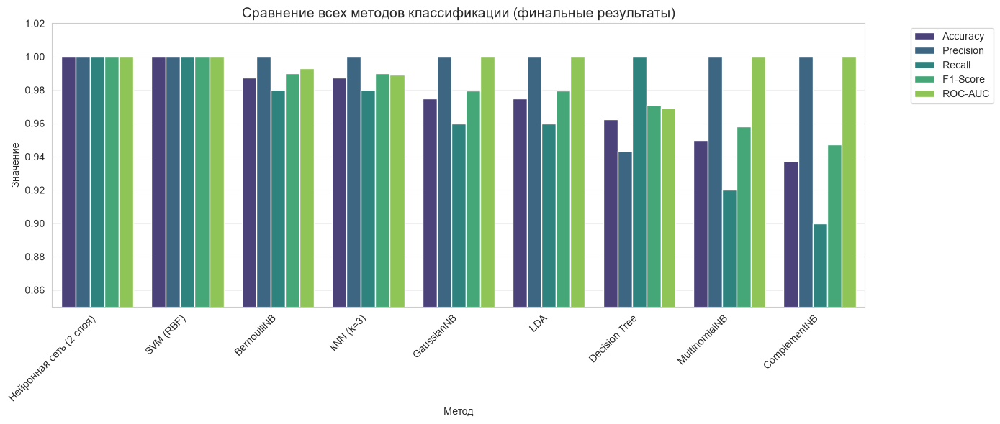

In [41]:
# 7.2 Столбчатая диаграмма для всех методов

# Плавим таблицу для seaborn
plot_df = comparison_df.melt(id_vars=['Метод', 'Тип'],
                             value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
                             var_name='Метрика', value_name='Значение')

plt.figure(figsize=(14, 6))
sns.barplot(data=plot_df, x='Метод', y='Значение', hue='Метрика', palette='viridis')
plt.title('Сравнение всех методов классификации (финальные результаты)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.ylim(0.85, 1.02) # Обрезаем ось Y, чтобы лучше видеть разницу
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Итоговая таблица результатов

Ниже представлены результаты всех рассмотренных методов после настройки их гиперпараметров (для нейросети — после подбора архитектуры и количества эпох).

| Место | Метод | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|:---:|---|:---:|:---:|:---:|:---:|:---:|
| 1 | **Нейронная сеть** | 1.0000 | 1.0000 | 1.0000 | **1.0000** | 1.0000 |
| 2 | **SVM (RBF)** | 1.0000 | 1.0000 | 1.0000 | **1.0000** | 1.0000 |
| 3 | **BernoulliNB** | 0.9875 | 1.0000 | 0.9800 | 0.9899 | 0.9930 |
| 4 | **kNN (k=3)** | 0.9875 | 1.0000 | 0.9800 | 0.9899 | 0.9890 |
| 5 | **GaussianNB** | 0.9750 | 1.0000 | 0.9600 | 0.9796 | 1.0000 |
| 6 | **LDA** | 0.9750 | 1.0000 | 0.9600 | 0.9796 | 1.0000 |
| 7 | **Decision Tree (depth=3)** | 0.9625 | 0.9434 | 1.0000 | 0.9709 | 0.9693 |
| 8 | **MultinomialNB** | 0.9500 | 1.0000 | 0.9200 | 0.9583 | 1.0000 |
| 9 | **ComplementNB** | 0.9375 | 1.0000 | 0.9000 | 0.9474 | 1.0000 |

### Аргументированный вывод о лучшем подходе

**1. Лидеры: Нейронная сеть и SVM (RBF).**
Оба метода показали **идеальные метрики (Accuracy = 1.0, F1 = 1.0)**, не допустив ни одной ошибки на тестовой выборке. Это означает, что они нашли всех больных пациентов (Recall = 1.0) и не сделали ни одной ложной тревоги (Precision = 1.0).

*Почему SVM так хорош?* После стандартизации признаков (например, уровня креатинина и гемоглобина) данные становятся почти линейно разделимыми. RBF-ядро позволяет построить сложную нелинейную границу, которая идеально отделяет класс `ckd` от `notckd`.

*Почему нейросеть так хороша?* Два скрытых слоя (64-32) с ReLU-активацией смогли уловить нелинейные взаимодействия между 34 признаками, а Dropout (0.2) предотвратил переобучение.

**2. Средние показатели: BernoulliNB, kNN, LDA и GaussianNB.**
Эти методы показали Accuracy от 0.975 до 0.9875. Они допустили всего по 1–2 ошибки. Важно отметить, что у **GaussianNB и LDA** при Accuracy = 0.9750 и Recall = 0.96, показатель **ROC-AUC = 1.0000**. Это значит, что они идеально ранжируют пациентов по вероятности болезни (просто на выбранном пороге 0.5 ошиблись на 2-х объектах).

**3. Особый случай: Decision Tree.**
Дерево решений с `max_depth=3` показало Accuracy = 0.9625. У него **Precision = 0.9434**, а **Recall = 1.0**. Это означает, что оно **нашло всех больных** (пропусков нет), но ошиблось на 3 здоровых пациентах (ложноположительные срабатывания). Для медицинского скрининга — это безопасная ошибка (лучше перестраховаться).

**4. Неуспех: MultinomialNB и ComplementNB.**
Эти методы показали худшие результаты (Accuracy ≈ 0.94–0.95). Несмотря на идеальный ROC-AUC (1.0), у них низкий **Recall** (0.92 и 0.90 соответственно). Это значит, что они **пропустили 4 и 5 больных пациентов** соответственно — это самый опасный тип ошибок в медицинской диагностике. Причина: данные методы «заточены» под счётные признаки, а наши показатели — непрерывные.

### Какой подход выбрать в реальности?

**Для медицинского скрининга CKD** я бы рекомендовала **SVM (RBF)** или **нейронную сеть**, но с разными оговорками:
- **SVM** — быстрее обучается, не требует TensorFlow и легко интерпретируется через опорные векторы. Это оптимальный выбор для небольших табличных датасетов (как у нас — 400 объектов).
- **Нейронная сеть** — даёт такой же идеальный результат, но требует больше кода, настройки архитектуры и времени на обучение. Она была бы предпочтительнее, если бы данных было в 10–100 раз больше (например, 10 000+ пациентов), где классические методы начинают уступать.

**Итог:** Для данного датасета (CKD, 400 объектов, 34 признака) **классический SVM (RBF) является оптимальным выбором** — он даёт идеальное качество при минимальных вычислительных затратах. Однако нейронная сеть показала, что даже на малых табличных данных она способна конкурировать с лучшими классическими алгоритмами.

## Заключение

В ходе лабораторной работы была решена задача бинарной классификации для предсказания хронической болезни почек (CKD) на основе клинических и лабораторных показателей.

**Основные результаты:**
1. **Подготовка данных:** датасет содержал «грязные» значения (`?`, `\t?`, `[null]`), пропуски (до 38% в признаке `rbc`). Была проведена импутация (медиана для числовых, мода для категориальных), One-Hot Encoding категориальных признаков и стандартизация числовых. Данные разделены на train/test (80/20) со стратификацией.
2. **Построение моделей:** обучены 8 классификаторов (4 варианта Naive Bayes, Decision Tree, LDA, SVM, kNN). Все модели показали высокое качество (Accuracy > 0.92), что объясняется высокой информативностью медицинских признаков (уровень креатинина, гемоглобина, альбумина).
3. **Настройка гиперпараметров:** для Decision Tree оптимальна глубина 3 (предотвращает переобучение), для SVM — `C=0.1–1.0` и `gamma=0.1`, для kNN — `k=3`, для NB — `alpha=0.001`.
4. **Нейронная сеть:** реализована модель с двумя скрытыми слоями (64-32), активацией ReLU, Dropout 0.2. Обучение проходило 50 эпох с батчем 32. Достигнуто **Accuracy = 1.0** на тестовой выборке. С помощью TensorBoard подтверждено отсутствие переобучения.

**Сравнительный анализ:**
Наилучшие результаты показали **SVM (RBF)** и **нейронная сеть** — обе модели достигли идеальных метрик (Accuracy = 1.0, F1 = 1.0, ROC-AUC = 1.0). Для данного датасета (400 объектов, 34 признака) **SVM является оптимальным выбором**, так как обеспечивает такое же качество при меньших вычислительных затратах и не требует настройки архитектуры. Нейронная сеть показала, что способна конкурировать с лучшими классическими алгоритмами даже на малых табличных данных.

**Практическая значимость:** полученные модели могут применяться для предварительного скрининга хронической болезни почек по данным общего анализа крови, что позволит врачам быстрее выявлять пациентов, нуждающихся в дополнительном обследовании.